LAB05

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def show_images(images, titles, cmap='gray', figsize=(14, 6)):
    n = len(images)
    plt.figure(figsize=figsize)
    for i in range(n):
        plt.subplot(1, n, i + 1)
        if len(images[i].shape) == 2:
            plt.imshow(images[i], cmap=cmap)
        else:
            plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        plt.title(titles[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

#16 Bài tập cuối bài


##16.1 Bài tập 1. Làm sạch biên tế bào có gai nhỏ

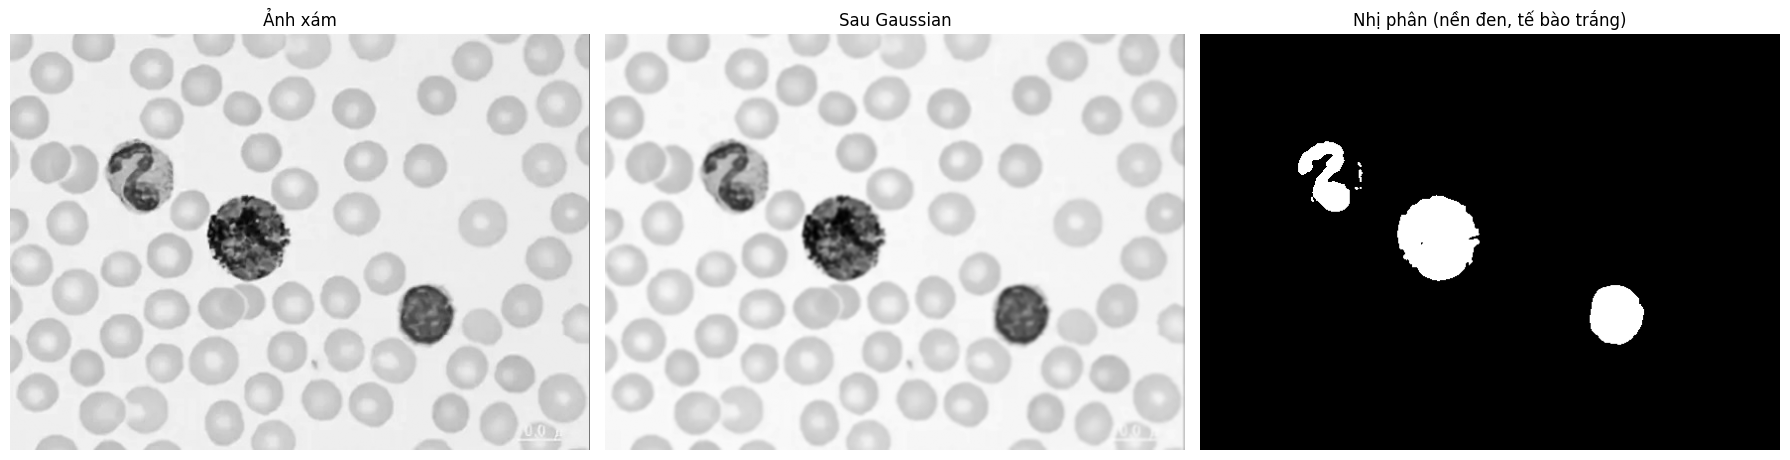

In [ ]:

img = cv2.imread("/content/WBC1.jpg", cv2.IMREAD_GRAYSCALE)
blur = cv2.GaussianBlur(img, (5, 5), 0)
_, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

show_images([img, blur, binary], ["Ảnh xám", "Sau Gaussian", "Nhị phân (nền đen, tế bào trắng)"], figsize=(18, 6))

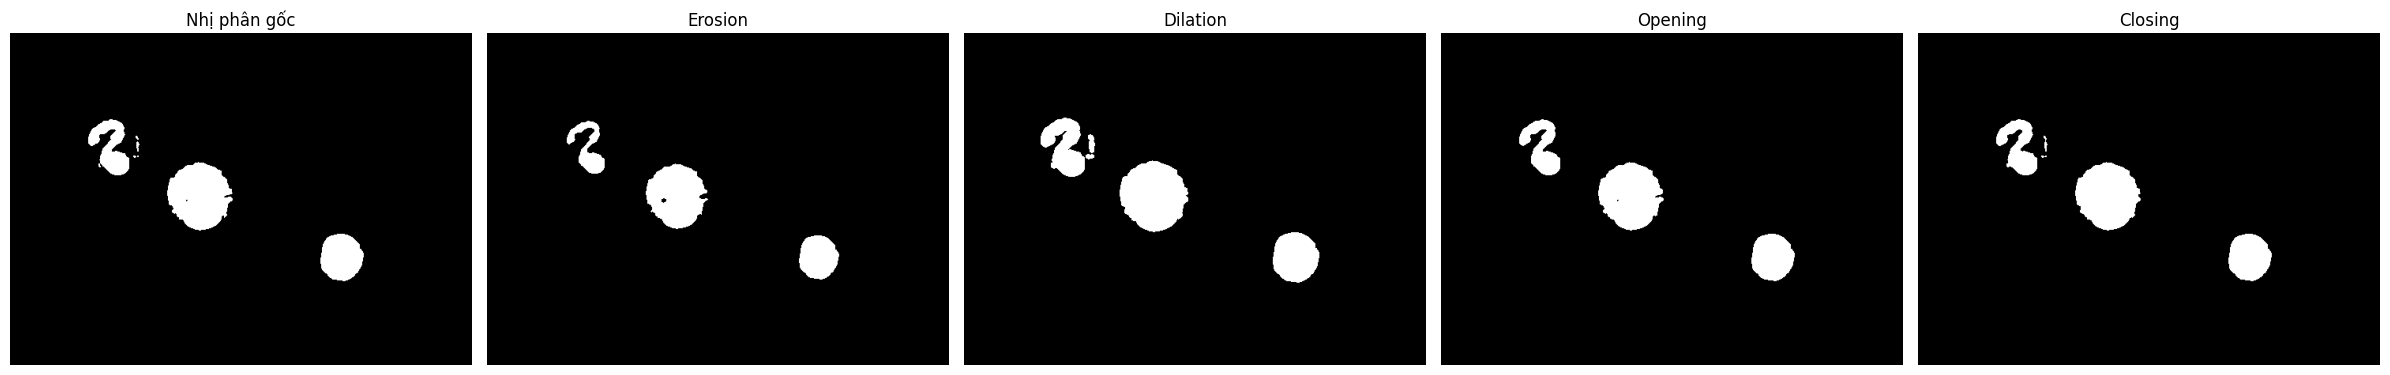

In [ ]:
# Áp dụng riêng từng phép erosion, dilation, opening, closing với cùng kernel ellipse 5x5
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

show_images(
    [binary, erosion, dilation, opening, closing],
    ["Nhị phân gốc", "Erosion", "Dilation", "Opening", "Closing"],
    figsize=(24, 5)
)

In [ ]:
# Đo diện tích, số đối tượng và tổng chu vi biên của từng kết quả để so sánh độ mượt và mức giữ hình dạng
def do_dac_trung(anh):
    dien_tich = cv2.countNonZero(anh)
    contours, _ = cv2.findContours(anh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    so_doi_tuong = len(contours)
    chu_vi = sum(cv2.arcLength(c, True) for c in contours)
    return dien_tich, so_doi_tuong, chu_vi

danh_sach = [("Nhị phân gốc", binary), ("Erosion", erosion), ("Dilation", dilation),
             ("Opening", opening), ("Closing", closing)]

area_goc = cv2.countNonZero(binary)
print(f"{'Phép':<14}{'Diện tích':>12}{'Thay đổi':>12}{'Số đối tượng':>15}{'Tổng chu vi':>14}")
for ten, anh in danh_sach:
    dt, n, cv_ = do_dac_trung(anh)
    thay_doi = (dt - area_goc) / area_goc * 100
    print(f"{ten:<14}{dt:>12}{thay_doi:>11.1f}%{n:>15}{cv_:>14.0f}")

Phép             Diện tích    Thay đổi   Số đối tượng   Tổng chu vi
Nhị phân gốc          9804        0.0%              7           867
Erosion               8178      -16.6%              3           751
Dilation             11576       18.1%              5           905
Opening               9706       -1.0%              3           792
Closing               9870        0.7%              5           840


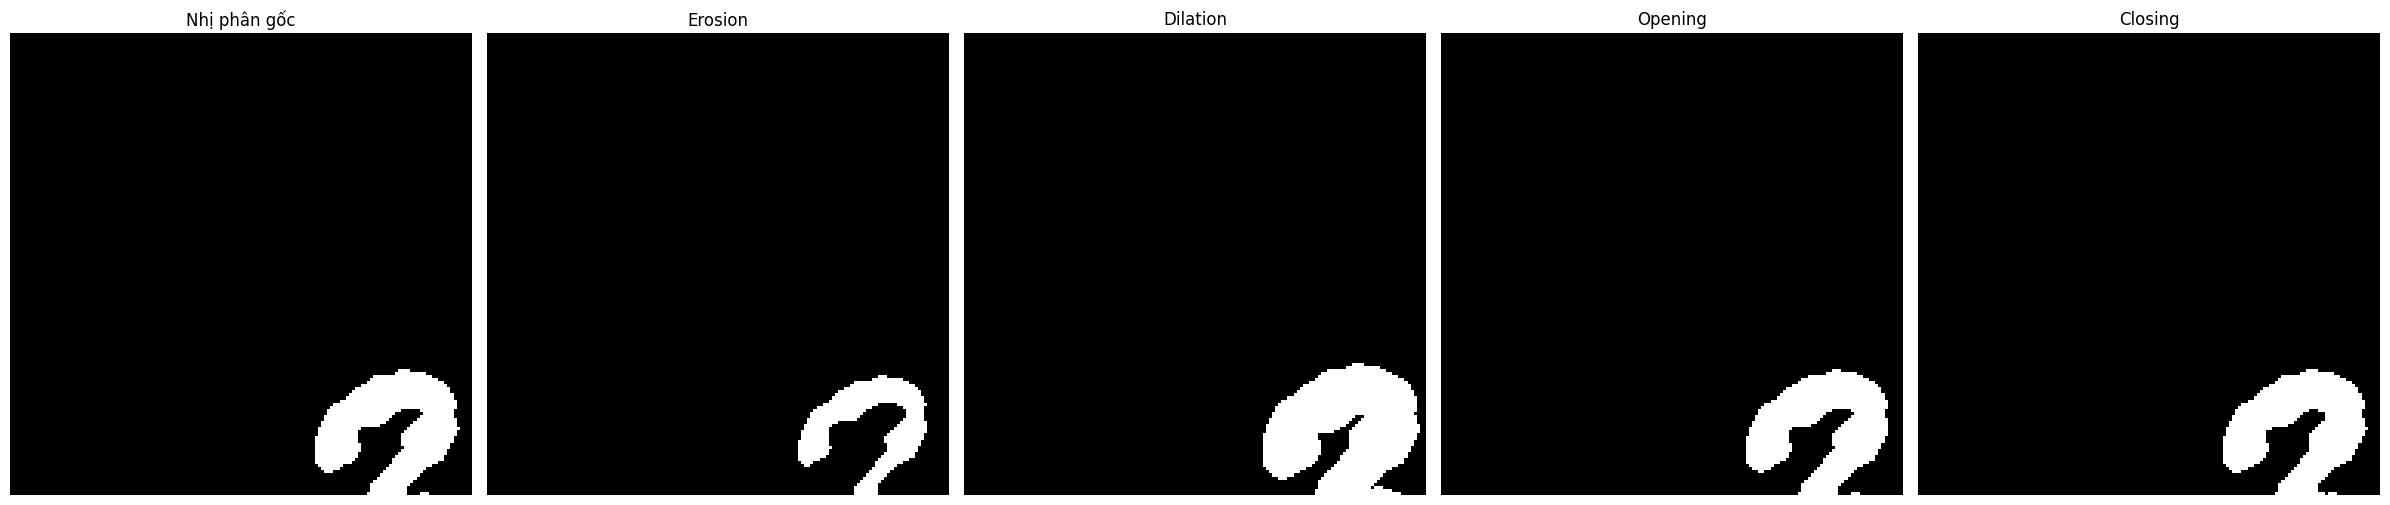

In [ ]:
# Phóng to một vùng của ảnh để nhìn rõ biên và các gai nhỏ trước và sau xử lý (đổi y1, y2, x1, x2 để chọn vùng khác)
y1, y2, x1, x2 = 0, 150, 0, 150

vung = [anh[y1:y2, x1:x2] for _, anh in danh_sach]
tieu_de = [ten for ten, _ in danh_sach]
show_images(vung, tieu_de, figsize=(24, 5))

Nhận xét và kết luận: làm sạch gai nhỏ ở biên (ảnh WBC, kernel ellipse 5x5)

**1. Bảng kết quả**

| Phép | Diện tích | Thay đổi | Số đối tượng | Tổng chu vi |
|---|---|---|---|---|
| Nhị phân gốc | 9804 | 0.0% | 7 | 867 |
| Erosion | 8178 | -16.6% | 3 | 751 |
| Dilation | 11576 | +18.1% | 5 | 905 |
| Opening | 9706 | -1.0% | 3 | 792 |
| Closing | 9870 | +0.7% | 5 | 840 |

**2. So sánh**
- **Độ mượt của biên:** ảnh gốc có 7 đối tượng, trong đó ba là tế bào và các vùng còn lại là chấm nhiễu nhỏ. Erosion và Opening đưa số đối tượng về 3, tức là loại bỏ các chấm nhiễu, đồng thời giảm tổng chu vi (751 và 792 so với 867). Dilation và Closing vẫn còn 5 đối tượng, chu vi của Dilation còn tăng lên (905), nghĩa là chấm nhiễu không bị loại mà còn dính hoặc to ra.
- **Mức giữ hình dạng tổng thể:** Opening giữ diện tích gần như nguyên (-1.0%) và Closing cũng gần như nguyên (+0.7%). Erosion làm diện tích giảm 16.6%, còn Dilation làm tăng 18.1%, nên hai phép này làm sai kích thước thật của tế bào.
- **Nguy cơ mất chi tiết thật:** Erosion có nguy cơ cao nhất vì co cả thân tế bào, các phần mảnh bị mỏng đi. Opening có nguy cơ thấp nếu kernel nhỏ hơn cấu trúc thật. Dilation làm gai và nhiễu dính vào tế bào. Closing không loại được gai.

**3. Kết luận**
Phép phù hợp nhất để khử gai nhỏ ở rìa là **Opening**. Opening loại được các chấm nhiễu và gai nhỏ (số đối tượng giảm từ 7 xuống 3, chu vi giảm từ 867 xuống 792) mà diện tích gần như không đổi (-1.0%). Erosion cũng loại được nhiễu nhưng làm tế bào co nhỏ, diện tích giảm tới 16.6%. Lý do là Opening = Erosion rồi Dilation: bước co bỏ chi tiết nhỏ, bước giãn khôi phục lại gần đúng kích thước chính. Dilation và Closing không phù hợp vì chúng mở rộng hoặc lấp vùng trắng chứ không loại bỏ phần nhô ra.

##16.2 Bài tập 2. Lấp lỗ nhỏ trong vùng tổn thương

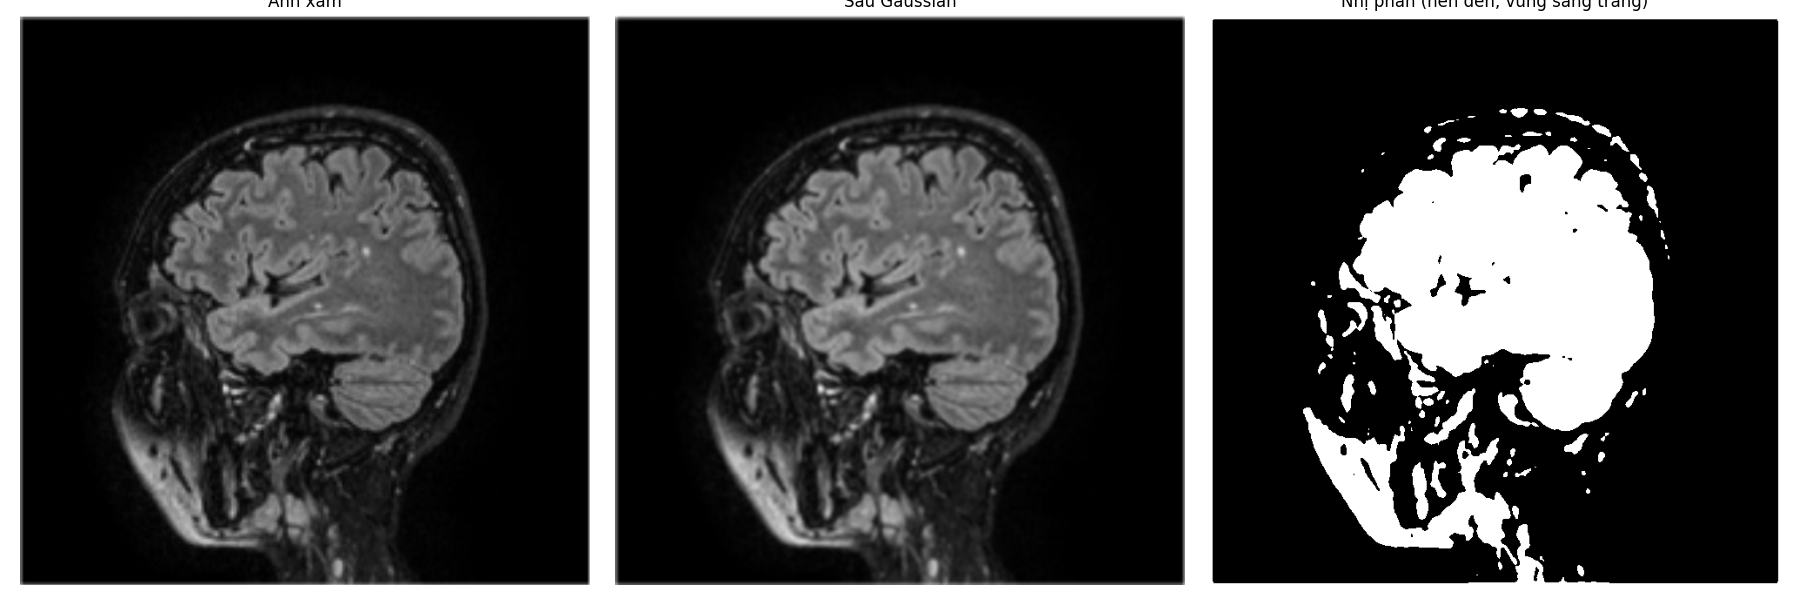

In [ ]:
# Đọc ảnh MRI não, làm mờ Gaussian và ngưỡng hóa Otsu (nền đen, vùng sáng trắng)
img = cv2.imread("/content/bone2.jpg", cv2.IMREAD_GRAYSCALE)
blur = cv2.GaussianBlur(img, (5, 5), 0)
_, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

show_images([img, blur, binary], ["Ảnh xám", "Sau Gaussian", "Nhị phân (nền đen, vùng sáng trắng)"], figsize=(18, 6))

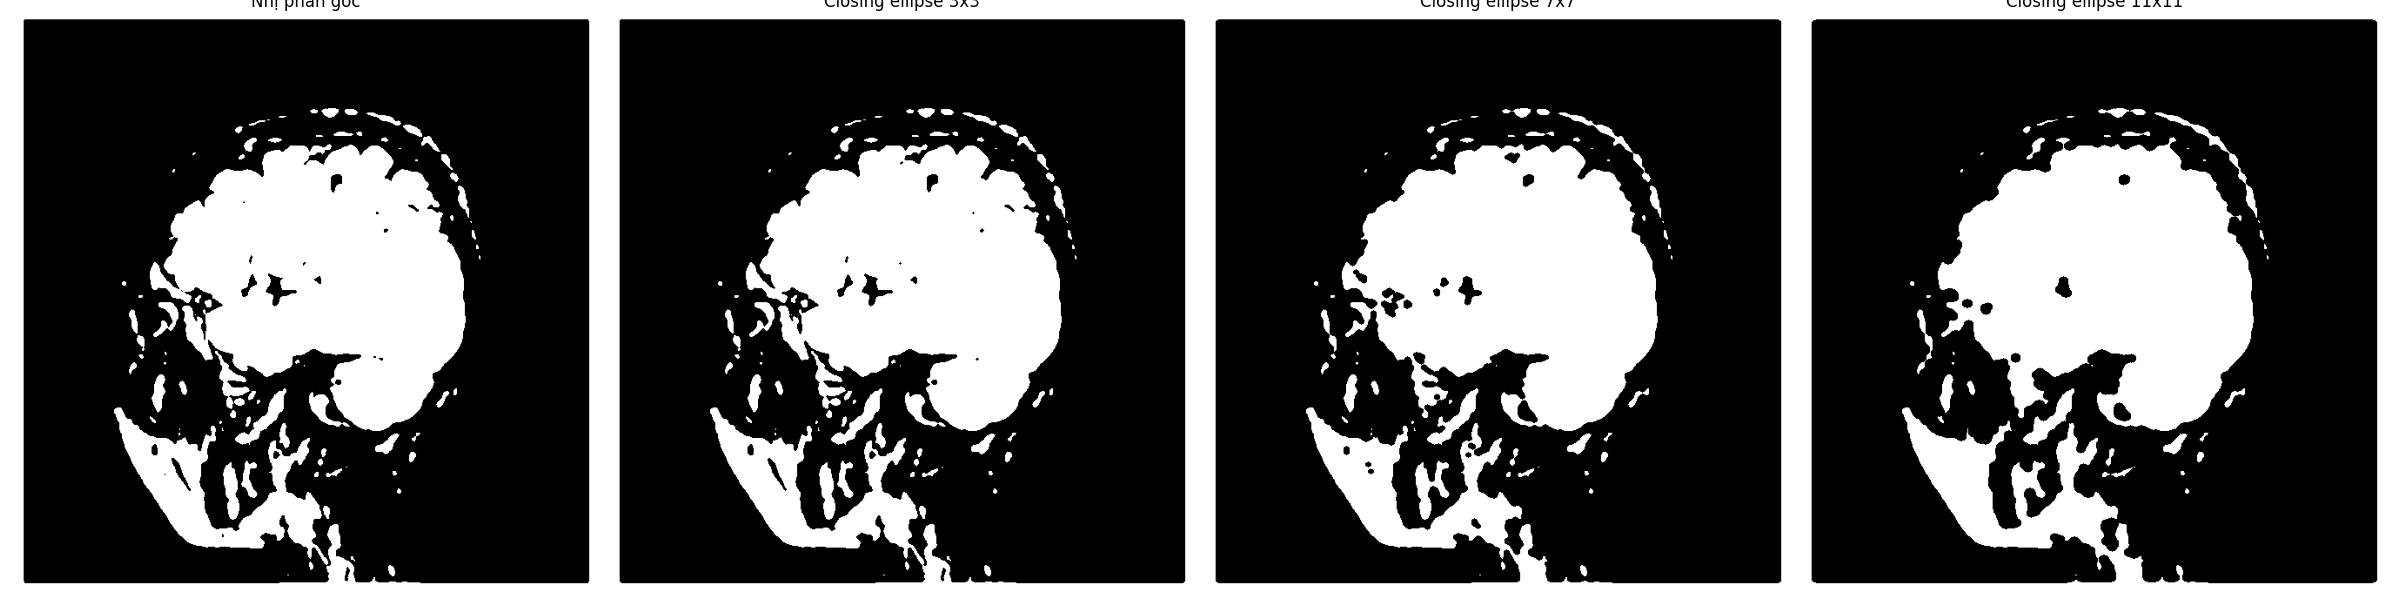

In [ ]:
# Closing với ba kích thước kernel ellipse (3,3), (7,7), (11,11)
kich_thuoc = [(3, 3), (7, 7), (11, 11)]
ket_qua = [cv2.morphologyEx(binary, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, k)) for k in kich_thuoc]

show_images(
    [binary] + ket_qua,
    ["Nhị phân gốc"] + [f"Closing ellipse {k[0]}x{k[1]}" for k in kich_thuoc],
    figsize=(24, 6)
)

In [ ]:
# Đo số lỗ nhỏ còn lại, phần trăm điểm ảnh lỗ được lấp, số điểm trắng thêm ra ngoài lỗ và số đối tượng
dt_lo_nho = 1000
dt_doi_tuong = 50

lo_nho = np.zeros_like(binary)
contours, hierarchy = cv2.findContours(binary, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
for c, h in zip(contours, hierarchy[0]):
    if h[3] != -1 and cv2.contourArea(c) < dt_lo_nho:
        cv2.drawContours(lo_nho, [c], -1, 255, -1)
lo_nho = cv2.bitwise_and(lo_nho, cv2.bitwise_not(binary))
tong_lo = cv2.countNonZero(lo_nho)

def dem_lo_va_doi_tuong(anh):
    contours, hierarchy = cv2.findContours(anh, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
    so_lo = sum(1 for c, h in zip(contours, hierarchy[0]) if h[3] != -1 and cv2.contourArea(c) < dt_lo_nho)
    so_dt = sum(1 for c, h in zip(contours, hierarchy[0]) if h[3] == -1 and cv2.contourArea(c) >= dt_doi_tuong)
    return so_lo, so_dt

so_lo_goc, so_dt_goc = dem_lo_va_doi_tuong(binary)
print(f"Số điểm ảnh thuộc lỗ nhỏ (diện tích < {dt_lo_nho}) trong ảnh gốc: {tong_lo}")
print(f"{'Ảnh':<20}{'Số lỗ nhỏ':>11}{'% lỗ được lấp':>15}{'Trắng thêm ngoài lỗ':>21}{'Số đối tượng':>14}")
print(f"{'Nhị phân gốc':<20}{so_lo_goc:>11}{0.0:>14.1f}%{0:>21}{so_dt_goc:>14}")
for k, anh in zip(kich_thuoc, ket_qua):
    so_lo, so_dt = dem_lo_va_doi_tuong(anh)
    da_lap = tong_lo - cv2.countNonZero(cv2.bitwise_and(lo_nho, cv2.bitwise_not(anh)))
    them_ngoai = cv2.countNonZero(anh) - cv2.countNonZero(binary) - da_lap
    print(f"{'Closing ' + str(k[0]) + 'x' + str(k[1]):<20}{so_lo:>11}{da_lap / tong_lo * 100:>14.1f}%{them_ngoai:>21}{so_dt:>14}")

Số điểm ảnh thuộc lỗ nhỏ (diện tích < 1000) trong ảnh gốc: 1462
Ảnh                   Số lỗ nhỏ  % lỗ được lấp  Trắng thêm ngoài lỗ  Số đối tượng
Nhị phân gốc                 21           0.0%                    0            32
Closing 3x3                  16           4.0%                   93            30
Closing 7x7                  17          40.3%                 1518            20
Closing 11x11                 6          69.8%                 4444            16


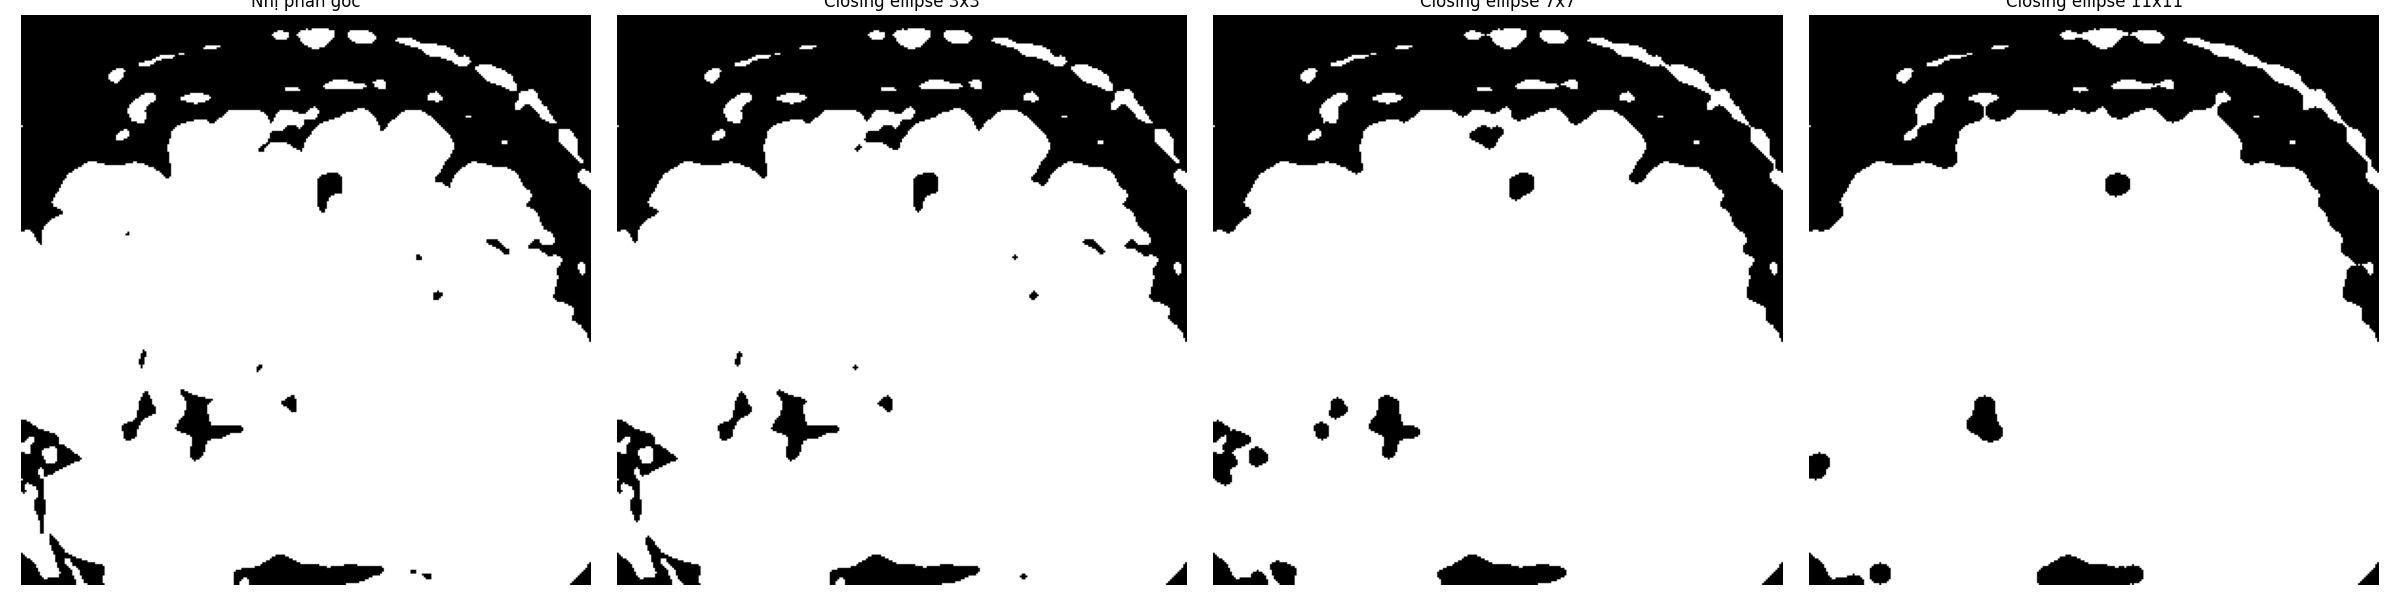

In [ ]:
# Phóng to vùng có nhiều lỗ và đường biên để nhìn rõ mức lấp lỗ và biến dạng biên (đổi y1, y2, x1, x2 để chọn vùng khác)
y1, y2, x1, x2 = 100, 400, 200, 500

vung = [anh[y1:y2, x1:x2] for anh in [binary] + ket_qua]
show_images(vung, ["Nhị phân gốc"] + [f"Closing ellipse {k[0]}x{k[1]}" for k in kich_thuoc], figsize=(24, 6))

Nhận xét và giải thích: lấp lỗ nhỏ bằng Closing (ảnh bone2, kernel ellipse 3x3, 7x7, 11x11)

**1. Bảng kết quả** (lỗ nhỏ là lỗ đen có diện tích dưới 1000 điểm ảnh, ảnh gốc có 21 lỗ với tổng 1462 điểm ảnh)

| Ảnh | Số lỗ nhỏ còn lại | % điểm ảnh lỗ được lấp | Điểm trắng thêm ngoài lỗ | Số đối tượng |
|---|---|---|---|---|
| Nhị phân gốc | 21 | 0.0% | 0 | 32 |
| Closing 3x3 | 16 | 4.0% | 93 | 30 |
| Closing 7x7 | 17 | 40.3% | 1518 | 20 |
| Closing 11x11 | 6 | 69.8% | 4444 | 16 |

**2. So sánh**
- **Khả năng lấp lỗ:** kernel 3x3 gần như không lấp được gì (chỉ 4.0% điểm ảnh lỗ), kernel 7x7 lấp 40.3% và kernel 11x11 lấp 69.8%, số lỗ nhỏ giảm từ 21 xuống 6. Số lỗ ở 7x7 (17) cao hơn 3x3 (16) có thể do một lỗ lớn bị thu nhỏ rồi lọt xuống dưới ngưỡng 1000 nên được đếm thêm, không phải do xuất hiện lỗ mới.
- **Biến dạng biên ngoài:** số điểm trắng thêm ngoài lỗ tăng nhanh theo kernel, từ 93 lên 1518 rồi 4444. Số đối tượng giảm từ 32 xuống 30, 20, 16 vì các mảnh nhỏ gần nhau (vùng da đầu, xương sọ) bị nối vào nhau hoặc nối vào vùng não. Ảnh phóng to cho thấy ở 11x11 các khe và rãnh nhỏ của biên não bị lấp, biên tròn hơn và mất chi tiết rãnh thật.
- **Hạn chế:** lỗ lớn hơn kernel vẫn còn (ví dụ các lỗ ở giữa vùng não). Ảnh này chỉ có 21 lỗ nhỏ sau Otsu nên kết luận dựa trên số lượng lỗ khá ít.

**3. Giải thích**
Closing = Dilation rồi Erosion. Bước giãn lấp được mọi lỗ và khe có bề rộng nhỏ hơn kernel, nên kernel càng lớn thì càng nhiều lỗ bị lấp. Nhưng bước giãn cũng lấp luôn các khe, rãnh và chỗ lõm thật của biên, và nối các vùng trắng ở gần nhau trong phạm vi kernel. Bước co sau đó chỉ trả lại phần mép ngoài, không làm hiện lại các chỗ đã bị lấp hoặc đã bị nối. Vì vậy kernel lớn lấp lỗ tốt hơn nhưng cũng làm hình dạng tổng thể thay đổi nhiều hơn, thể hiện qua số điểm trắng thêm ngoài lỗ tăng và số đối tượng giảm.

**Kết luận:** nên chọn kernel vừa đủ lớn hơn lỗ cần lấp. Ở ảnh này kernel 7x7 là điểm cân bằng tương đối (lấp 40.3% lỗ, thêm 1518 điểm ảnh), còn 11x11 lấp nhiều hơn nhưng biến dạng biên rõ.

##16.3 Bài tập 3. So sánh hai chuỗi phép toán

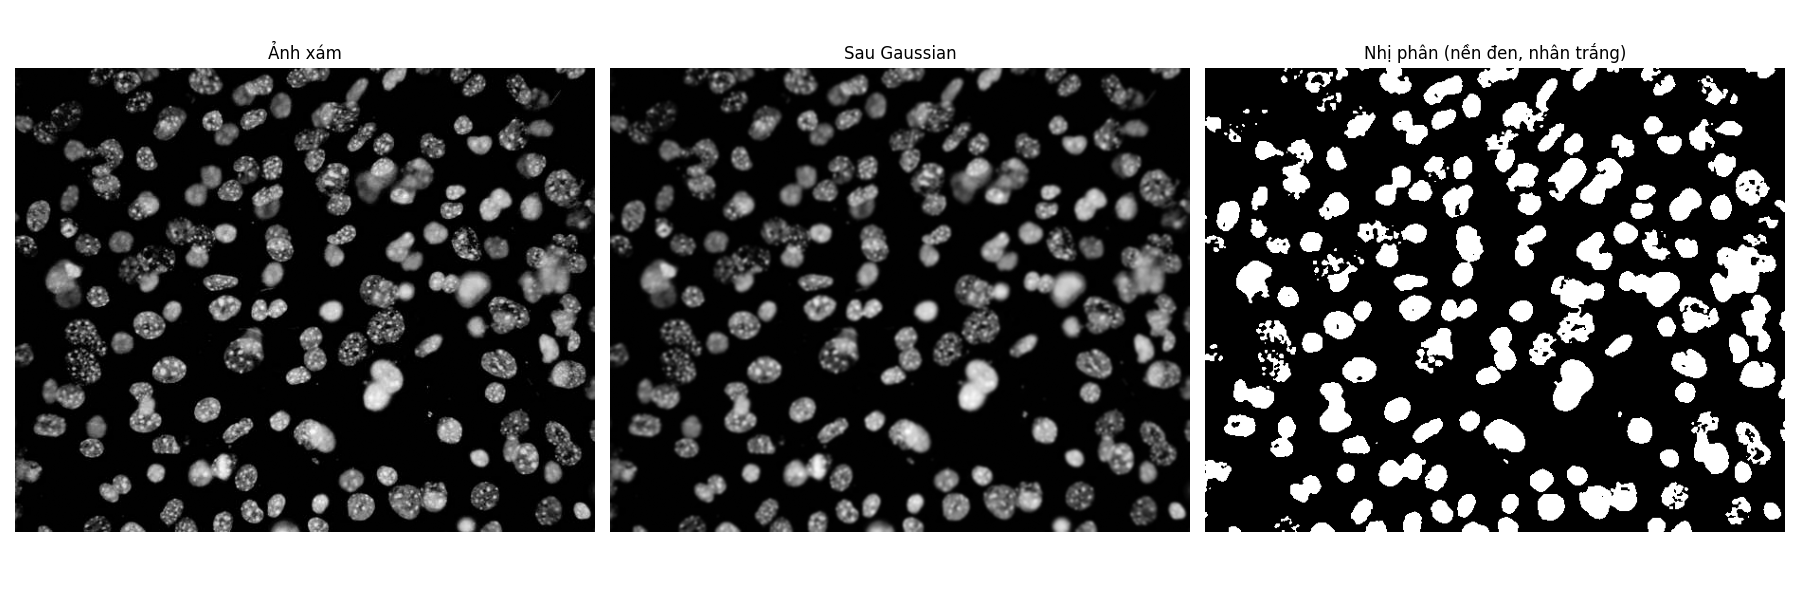

In [ ]:
# Đọc ảnh nhân tế bào, làm mờ Gaussian và ngưỡng hóa Otsu (nền đen, nhân trắng)
img = cv2.imread("/content/cell1.jpg", cv2.IMREAD_GRAYSCALE)
blur = cv2.GaussianBlur(img, (5, 5), 0)
_, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

show_images([img, blur, binary], ["Ảnh xám", "Sau Gaussian", "Nhị phân (nền đen, nhân trắng)"], figsize=(18, 6))

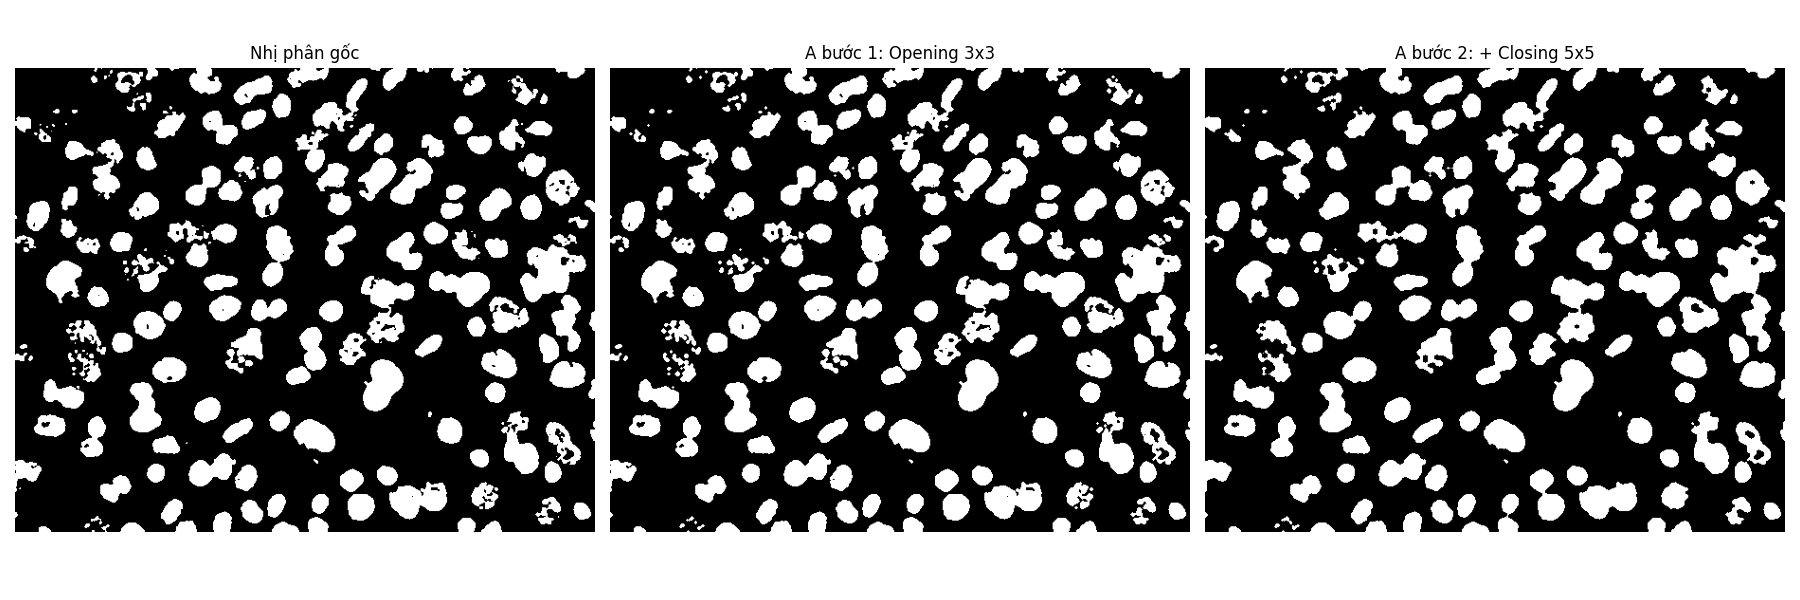

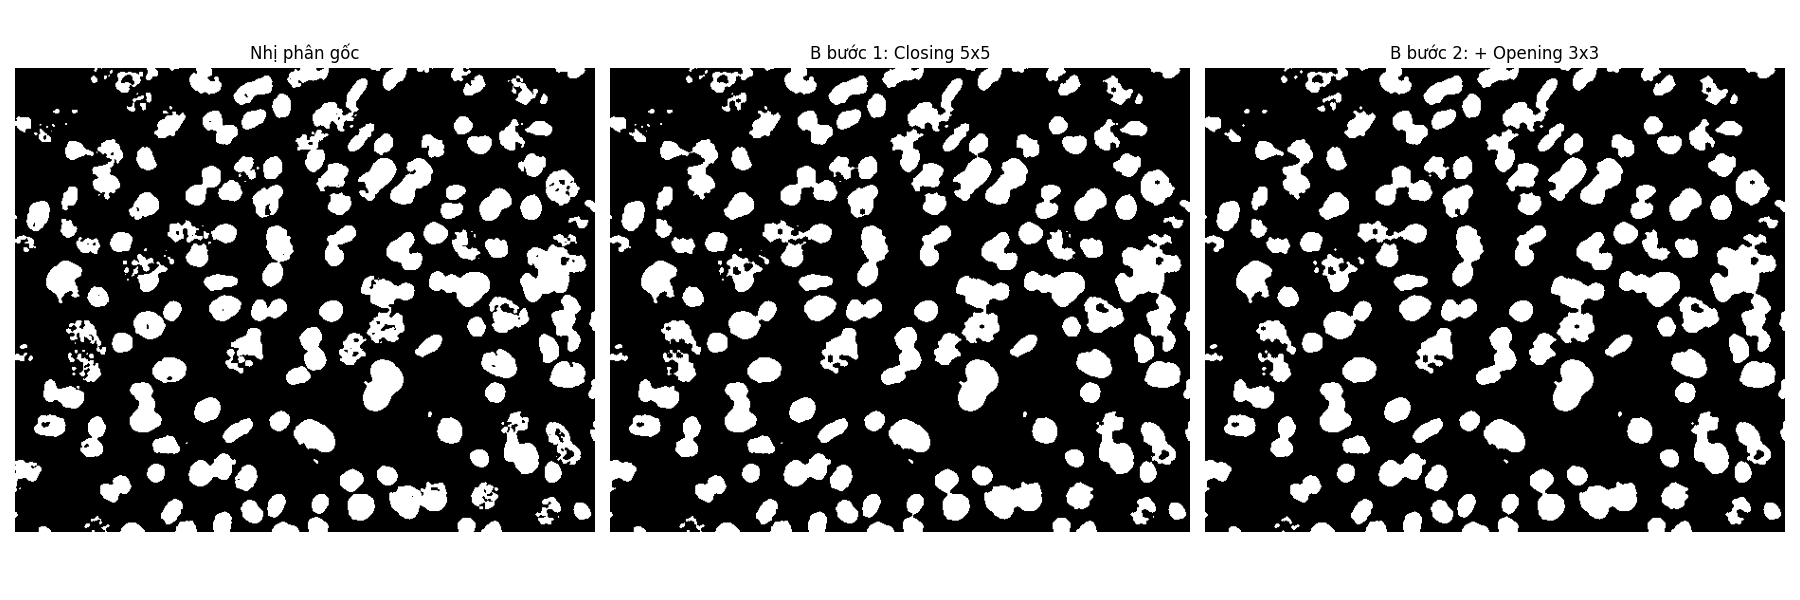

In [ ]:
# Tạo pipeline A (Opening -> Closing) và pipeline B (Closing -> Opening), hiển thị từng bước
kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

a_buoc1 = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel_open)
a_buoc2 = cv2.morphologyEx(a_buoc1, cv2.MORPH_CLOSE, kernel_close)
b_buoc1 = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel_close)
b_buoc2 = cv2.morphologyEx(b_buoc1, cv2.MORPH_OPEN, kernel_open)

show_images([binary, a_buoc1, a_buoc2], ["Nhị phân gốc", "A bước 1: Opening 3x3", "A bước 2: + Closing 5x5"], figsize=(18, 6))
show_images([binary, b_buoc1, b_buoc2], ["Nhị phân gốc", "B bước 1: Closing 5x5", "B bước 2: + Opening 3x3"], figsize=(18, 6))

In [ ]:
# Đếm chấm nhiễu, lỗ nhỏ, đo chu vi và diện tích của ảnh gốc và từng bước của hai pipeline
dt_nho = 50

def do_dac_trung(anh):
    contours, hierarchy = cv2.findContours(anh, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
    ngoai = [c for c, h in zip(contours, hierarchy[0]) if h[3] == -1]
    lo = [c for c, h in zip(contours, hierarchy[0]) if h[3] != -1]
    so_nhieu = sum(1 for c in ngoai if cv2.contourArea(c) < dt_nho)
    so_lo_nho = sum(1 for c in lo if cv2.contourArea(c) < dt_nho)
    chu_vi = sum(cv2.arcLength(c, True) for c in ngoai)
    return cv2.countNonZero(anh), len(ngoai) - so_nhieu, so_nhieu, so_lo_nho, chu_vi

danh_sach = [("Nhị phân gốc", binary), ("A: Opening", a_buoc1), ("A: Opening -> Closing", a_buoc2),
             ("B: Closing", b_buoc1), ("B: Closing -> Opening", b_buoc2)]

area_goc = cv2.countNonZero(binary)
print(f"{'Ảnh':<24}{'Diện tích':>11}{'Thay đổi':>10}{'Số nhân':>9}{'Chấm nhiễu':>12}{'Lỗ nhỏ':>8}{'Tổng chu vi':>13}")
for ten, anh in danh_sach:
    dt, n_nhan, n_nhieu, n_lo, cv_ = do_dac_trung(anh)
    print(f"{ten:<24}{dt:>11}{(dt - area_goc) / area_goc * 100:>9.1f}%{n_nhan:>9}{n_nhieu:>12}{n_lo:>8}{cv_:>13.0f}")
print("Số điểm ảnh khác nhau giữa kết quả cuối của A và B:", cv2.countNonZero(cv2.absdiff(a_buoc2, b_buoc2)))

Ảnh                       Diện tích  Thay đổi  Số nhân  Chấm nhiễu  Lỗ nhỏ  Tổng chu vi
Nhị phân gốc                  74554      0.0%      135          79      56        14812
A: Opening                    73997     -0.7%      135          61      42        14678
A: Opening -> Closing         76082      2.0%      123          33       7        13814
B: Closing                    76876      3.1%      122          41       9        14048
B: Closing -> Opening         76462      2.6%      125          33       7        13768
Số điểm ảnh khác nhau giữa kết quả cuối của A và B: 434


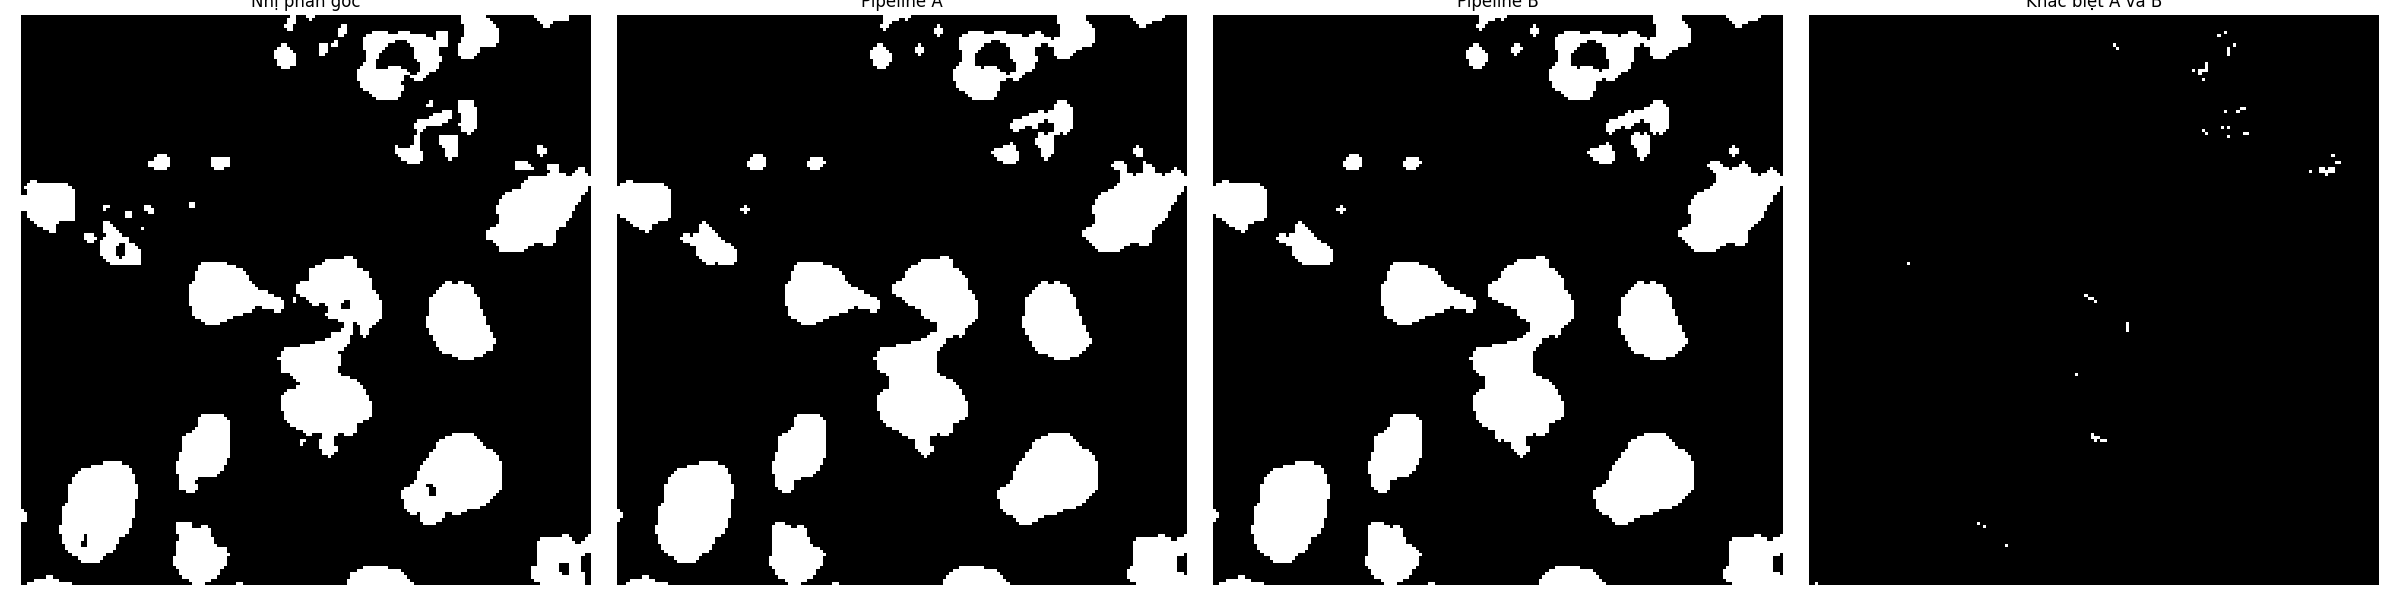

In [ ]:
# Phóng to một vùng của kết quả cuối để so sánh biên và chi tiết còn lại của hai pipeline (đổi y1, y2, x1, x2 để chọn vùng khác)
y1, y2, x1, x2 = 0, 180, 0, 180

show_images(
    [binary[y1:y2, x1:x2], a_buoc2[y1:y2, x1:x2], b_buoc2[y1:y2, x1:x2], cv2.absdiff(a_buoc2, b_buoc2)[y1:y2, x1:x2]],
    ["Nhị phân gốc", "Pipeline A", "Pipeline B", "Khác biệt A và B"],
    figsize=(24, 6)
)

Nhận xét và giải thích: so sánh hai pipeline (ảnh cell1, Opening ellipse 3x3 và Closing ellipse 5x5)

**1. Bảng kết quả** (chấm nhiễu và lỗ nhỏ là đối tượng, lỗ có diện tích dưới 50 điểm ảnh)

| Ảnh | Diện tích | Thay đổi | Số nhân | Chấm nhiễu | Lỗ nhỏ | Tổng chu vi |
|---|---|---|---|---|---|---|
| Nhị phân gốc | 74554 | 0.0% | 135 | 79 | 56 | 14812 |
| A: Opening | 73997 | -0.7% | 135 | 61 | 42 | 14678 |
| A: Opening -> Closing | 76082 | +2.0% | 123 | 33 | 7 | 13814 |
| B: Closing | 76876 | +3.1% | 122 | 41 | 9 | 14048 |
| B: Closing -> Opening | 76462 | +2.6% | 125 | 33 | 7 | 13768 |

**2. So sánh**
- **Số điểm nhiễu còn lại:** kết quả cuối của hai pipeline đều còn 33 chấm nhiễu (từ 79). Khác biệt nằm ở bước giữa: sau bước 1, A còn 61 chấm nhiễu còn B còn 41, vì Closing nối nhiều chấm vào nhân hoặc vào nhau.
- **Số lỗ nhỏ còn lại:** cả hai cùng còn 7 lỗ (từ 56). Sau bước 1, Closing đã lấp gần hết (còn 9 lỗ) còn Opening chỉ giảm còn 42 lỗ.
- **Độ mượt của biên:** tổng chu vi của B (13768) nhỉnh hơn A (13814) một chút, chênh lệch khoảng 0.3% nên độ mượt của hai kết quả gần như nhau.
- **Giữ kích thước vật thể:** A tăng diện tích 2.0% còn B tăng 2.6%. A gộp nhân nhiều hơn (còn 123 nhân so với 125 của B). Hai kết quả cuối chỉ khác nhau 434 điểm ảnh (khoảng 0.6% diện tích), ảnh phóng to cho thấy chỗ khác nhau là các chấm nhỏ rải rác ở rìa nhân.

**3. Giải thích**
Opening và Closing không giao hoán, thứ tự quyết định chi tiết nào bị xử lý trước. Với A, Opening bỏ các chấm sáng nhỏ trước, rồi Closing chỉ lấp lỗ trên hình đã sạch hơn nên ít chấm nhiễu bị nối vào nhân. Với B, Closing chạy trước nên các chấm gần nhân bị nối vào nhân (diện tích tăng 3.1% ngay ở bước 1) hoặc dính với nhau thành mảng lớn hơn; sau đó Opening 3x3 không còn loại được những mảng đó mà chỉ làm mòn biên. Trên ảnh này kernel nhỏ nên khác biệt cuối cùng nhỏ; kết quả chỉ tách rõ khi nhiễu nằm sát đối tượng hoặc kernel lớn.

**Kết luận:** pipeline A (Opening -> Closing) hợp lý hơn về nguyên tắc vì khử nhiễu trước rồi lấp lỗ sau, và ở đây giữ diện tích sát gốc hơn B (+2.0% so với +2.6%), nhưng với số liệu hiện tại hai pipeline khá gần nhau.

##16.4 Bài tập 4. Tách các tế bào dính nhau nhẹ

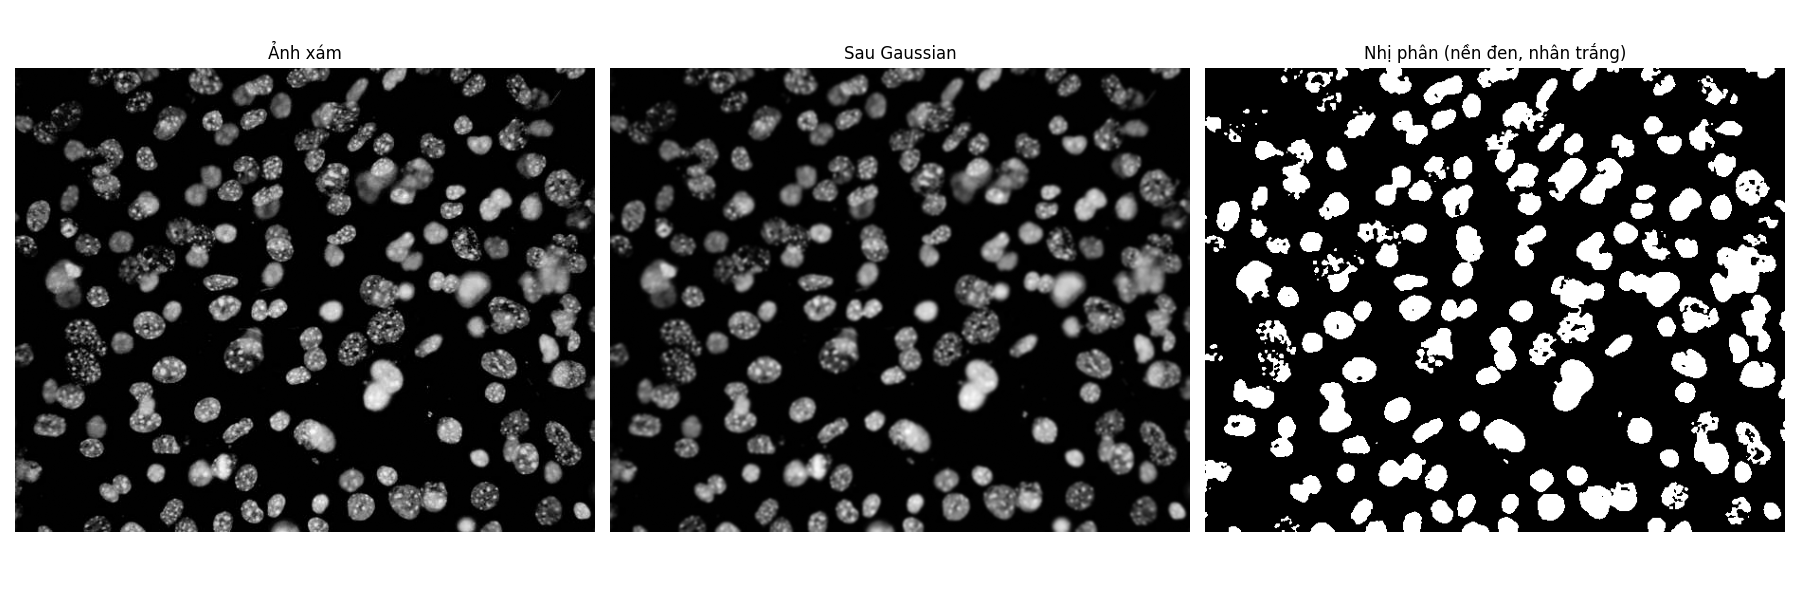

In [ ]:
# Đọc ảnh nhân tế bào, làm mờ Gaussian và ngưỡng hóa Otsu (nền đen, nhân trắng)
img = cv2.imread("/content/cell1.jpg", cv2.IMREAD_GRAYSCALE)
blur = cv2.GaussianBlur(img, (5, 5), 0)
_, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

show_images([img, blur, binary], ["Ảnh xám", "Sau Gaussian", "Nhị phân (nền đen, nhân trắng)"], figsize=(18, 6))

Kernel 3x3: erode->dilate giống opening hoàn toàn: True | số điểm ảnh khác nhau: 0
Kernel 5x5: erode->dilate giống opening hoàn toàn: True | số điểm ảnh khác nhau: 0
Kernel 7x7: erode->dilate giống opening hoàn toàn: True | số điểm ảnh khác nhau: 0
Kernel 9x9: erode->dilate giống opening hoàn toàn: True | số điểm ảnh khác nhau: 0


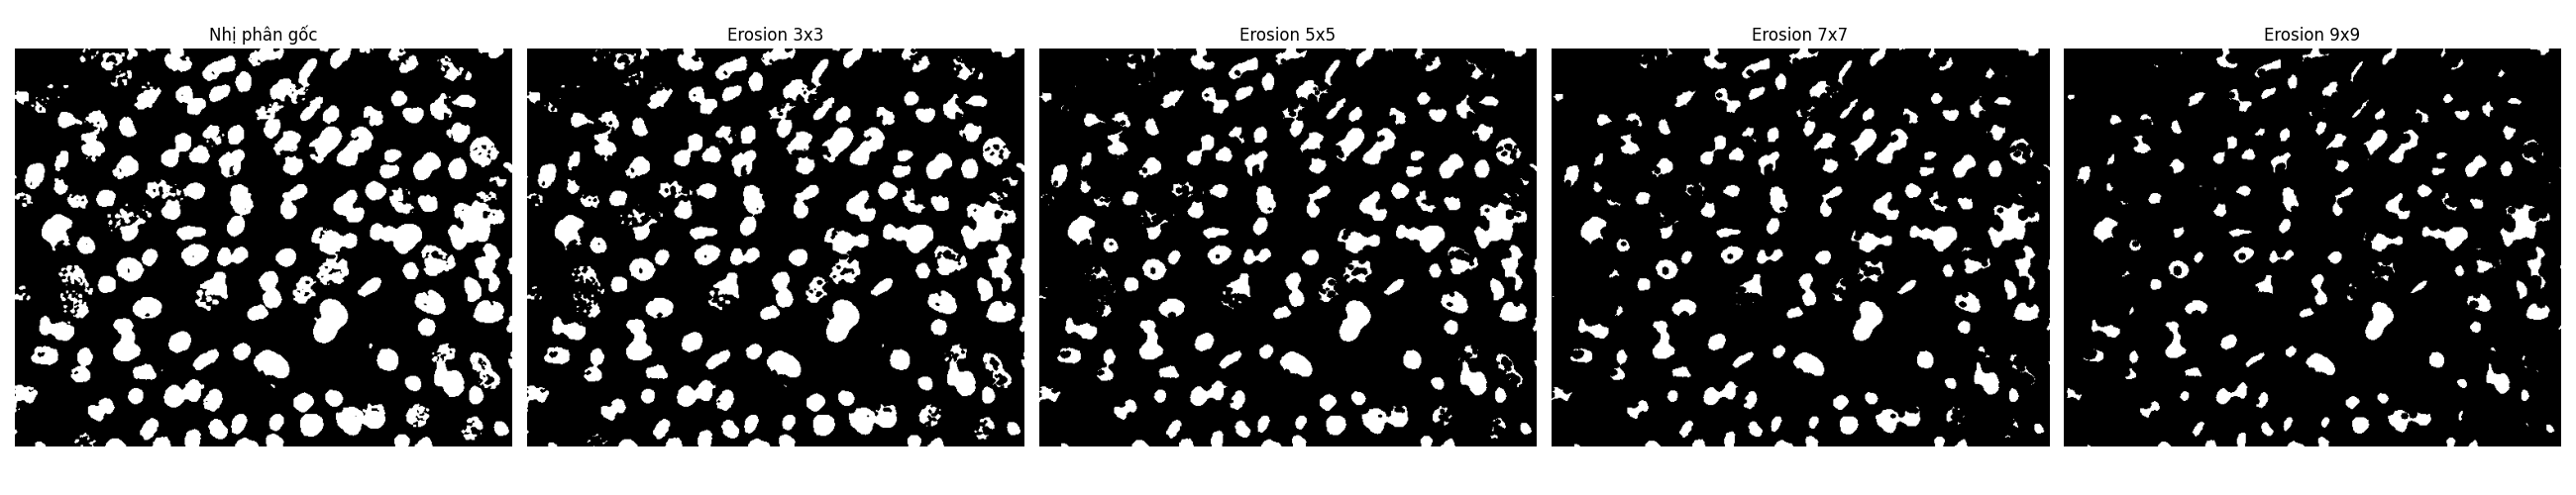

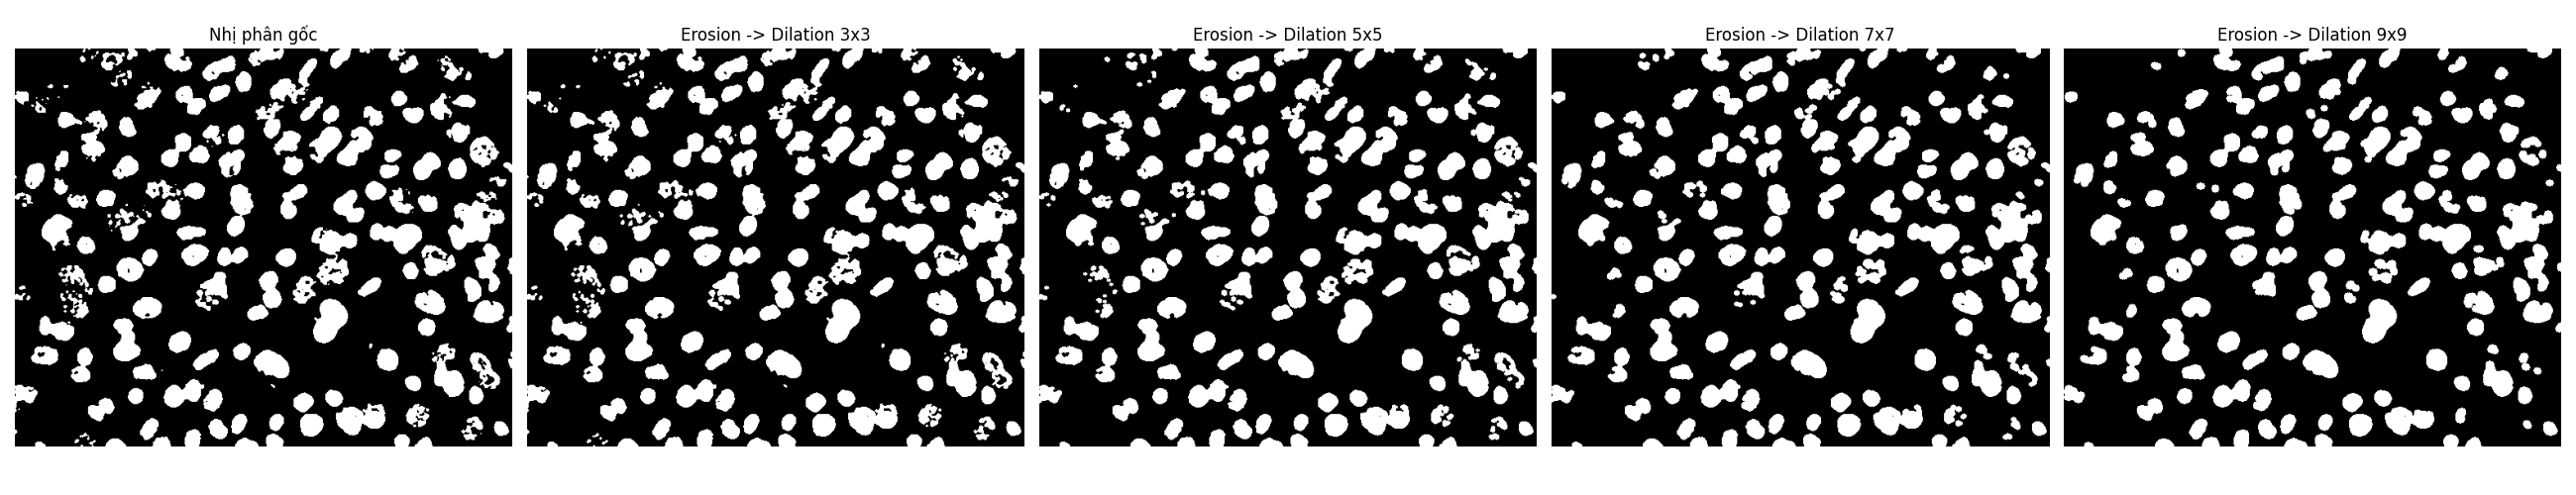

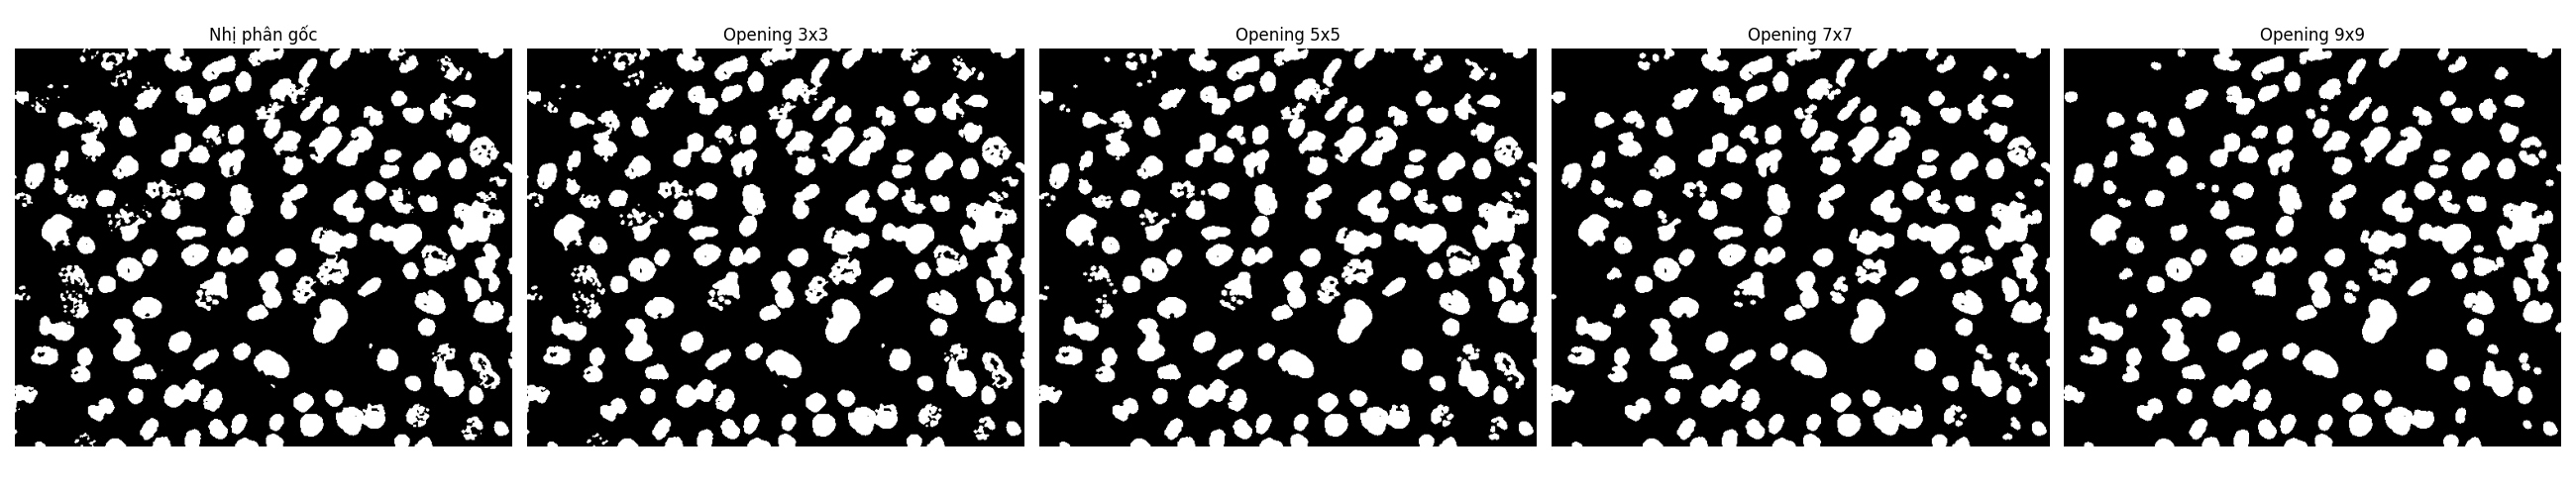

In [ ]:
# Erosion với kernel ellipse tăng dần, rồi dilation cùng kernel để phục hồi kích thước, so với Opening của OpenCV
kich_thuoc = [(3, 3), (5, 5), (7, 7), (9, 9)]
kernels = [cv2.getStructuringElement(cv2.MORPH_ELLIPSE, k) for k in kich_thuoc]

co = [cv2.erode(binary, k, iterations=1) for k in kernels]
co_roi_gian = [cv2.dilate(e, k, iterations=1) for e, k in zip(co, kernels)]
mo_opencv = [cv2.morphologyEx(binary, cv2.MORPH_OPEN, k) for k in kernels]

show_images([binary] + co, ["Nhị phân gốc"] + [f"Erosion {k[0]}x{k[1]}" for k in kich_thuoc], figsize=(26, 5))
show_images([binary] + co_roi_gian, ["Nhị phân gốc"] + [f"Erosion -> Dilation {k[0]}x{k[1]}" for k in kich_thuoc], figsize=(26, 5))
show_images([binary] + mo_opencv, ["Nhị phân gốc"] + [f"Opening {k[0]}x{k[1]}" for k in kich_thuoc], figsize=(26, 5))

for k, a, b in zip(kich_thuoc, co_roi_gian, mo_opencv):
    print(f"Kernel {k[0]}x{k[1]}: erode->dilate giống opening hoàn toàn:", np.array_equal(a, b), "| số điểm ảnh khác nhau:", cv2.countNonZero(cv2.absdiff(a, b)))

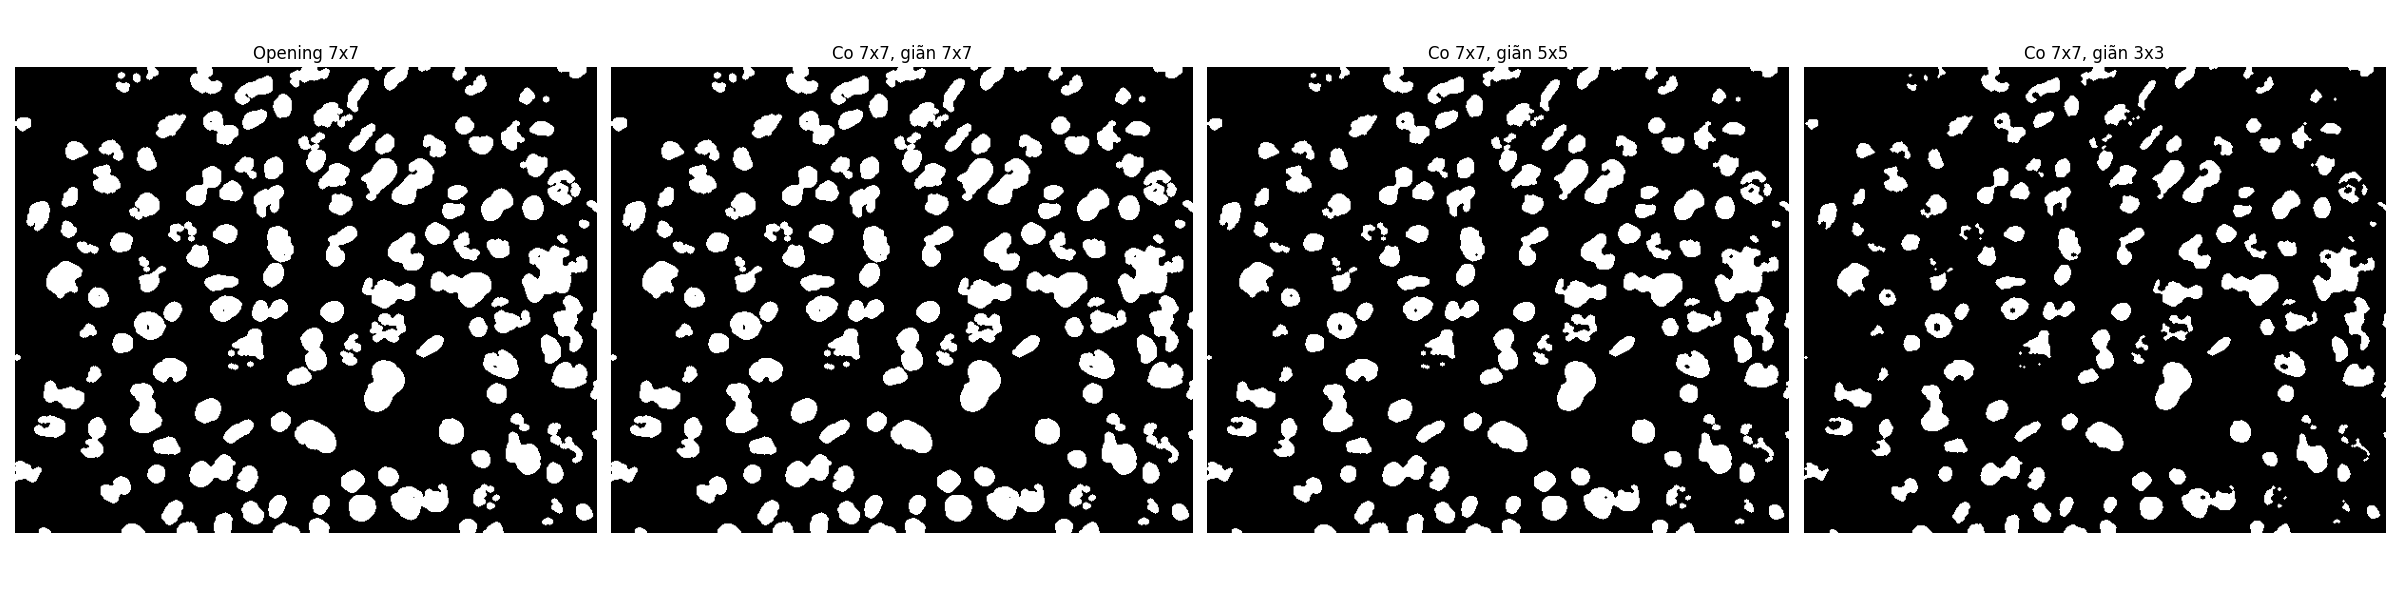

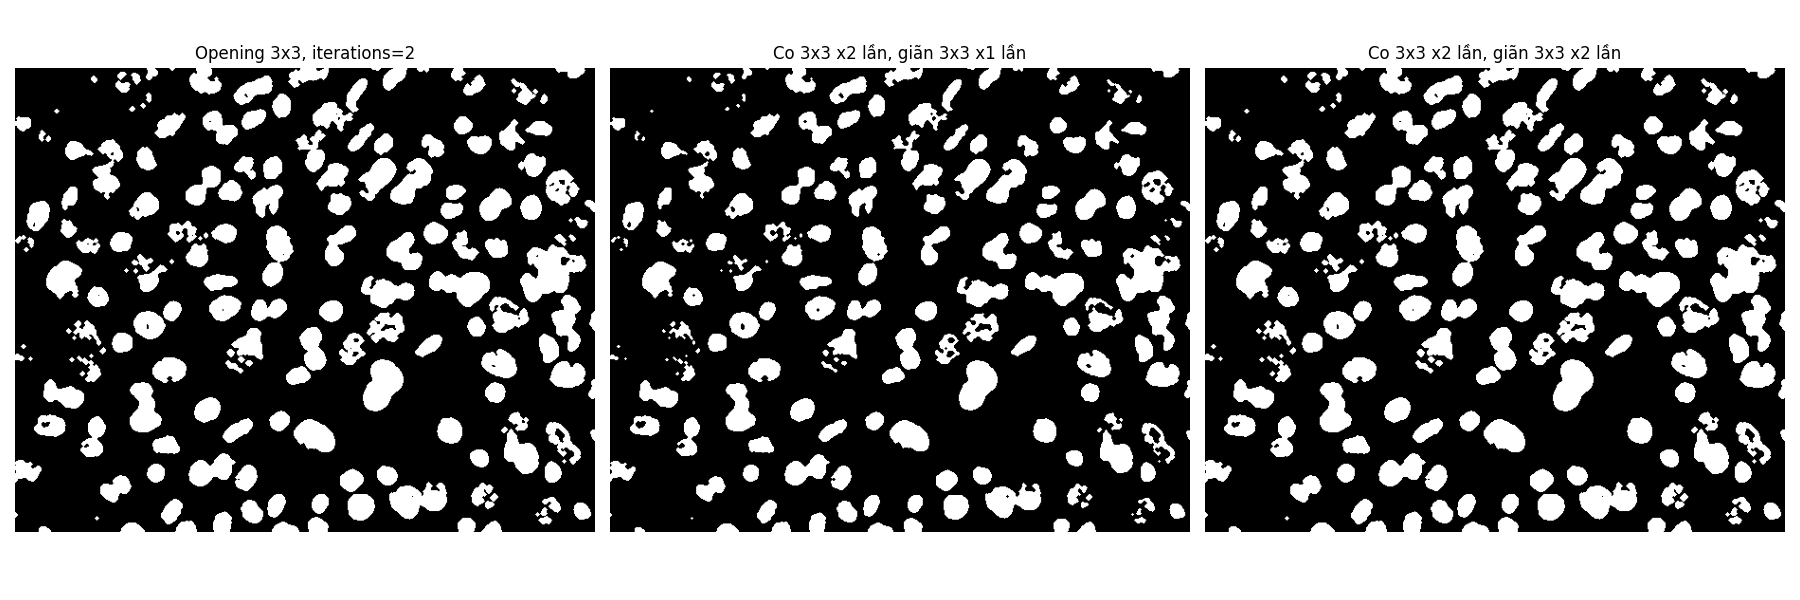

In [ ]:
# Thử co và giãn với kernel hoặc iterations khác nhau rồi so sánh với Opening cùng kernel của lệnh co
k3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
k5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
k7 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

bien_the = [
    ("Co 7x7, giãn 7x7", cv2.dilate(cv2.erode(binary, k7), k7)),
    ("Co 7x7, giãn 5x5", cv2.dilate(cv2.erode(binary, k7), k5)),
    ("Co 7x7, giãn 3x3", cv2.dilate(cv2.erode(binary, k7), k3)),
    ("Co 3x3 x2 lần, giãn 3x3 x1 lần", cv2.dilate(cv2.erode(binary, k3, iterations=2), k3, iterations=1)),
    ("Co 3x3 x2 lần, giãn 3x3 x2 lần", cv2.dilate(cv2.erode(binary, k3, iterations=2), k3, iterations=2)),
]
mo_k7 = cv2.morphologyEx(binary, cv2.MORPH_OPEN, k7)
mo_k3_2 = cv2.morphologyEx(binary, cv2.MORPH_OPEN, k3, iterations=2)

show_images(
    [mo_k7] + [anh for ten, anh in bien_the[:3]],
    ["Opening 7x7"] + [ten for ten, anh in bien_the[:3]],
    figsize=(24, 6)
)
show_images(
    [mo_k3_2] + [anh for ten, anh in bien_the[3:]],
    ["Opening 3x3, iterations=2"] + [ten for ten, anh in bien_the[3:]],
    figsize=(18, 6)
)

In [ ]:
# Đo diện tích và số nhân của erosion, các cách phục hồi và Opening để so sánh
dt_nhan = 100

def do_dac_trung(anh):
    contours, _ = cv2.findContours(anh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    return cv2.countNonZero(anh), sum(1 for c in contours if cv2.contourArea(c) >= dt_nhan)

area_goc, nhan_goc = do_dac_trung(binary)
danh_sach = [("Nhị phân gốc", binary)]
for k, e, d, o in zip(kich_thuoc, co, co_roi_gian, mo_opencv):
    danh_sach += [(f"Erosion {k[0]}x{k[1]}", e), (f"Erosion -> Dilation {k[0]}x{k[1]}", d), (f"Opening {k[0]}x{k[1]}", o)]
danh_sach += bien_the[1:4] + [("Opening 3x3, iterations=2", mo_k3_2)]

print(f"{'Ảnh':<36}{'Diện tích':>11}{'Thay đổi':>10}{'Số nhân':>9}{'Thay đổi':>10}")
for ten, anh in danh_sach:
    dt, n = do_dac_trung(anh)
    print(f"{ten:<36}{dt:>11}{(dt - area_goc) / area_goc * 100:>9.1f}%{n:>9}{n - nhan_goc:>+10}")
print(f"(Chỉ tính đối tượng có diện tích từ {dt_nhan} điểm ảnh trở lên là một nhân)")
print("Co 7x7 giãn 7x7 giống Opening 7x7:", np.array_equal(bien_the[0][1], mo_k7))
print("Co 3x3 x2 giãn 3x3 x2 giống Opening 3x3 iterations=2:", np.array_equal(bien_the[4][1], mo_k3_2))
print("Co 3x3 x2 giãn 3x3 x1 giống Opening 3x3 iterations=2:", np.array_equal(bien_the[3][1], mo_k3_2))

Ảnh                                   Diện tích  Thay đổi  Số nhân  Thay đổi
Nhị phân gốc                              74554      0.0%      127        +0
Erosion 3x3                               61351    -17.7%      124        -3
Erosion -> Dilation 3x3                   73997     -0.7%      127        +0
Opening 3x3                               73997     -0.7%      127        +0
Erosion 5x5                               46305    -37.9%      116       -11
Erosion -> Dilation 5x5                   71864     -3.6%      130        +3
Opening 5x5                               71864     -3.6%      130        +3
Erosion 7x7                               36312    -51.3%      103       -24
Erosion -> Dilation 7x7                   68981     -7.5%      130        +3
Opening 7x7                               68981     -7.5%      130        +3
Erosion 9x9                               26243    -64.8%       82       -45
Erosion -> Dilation 9x9                   64932    -12.9%      126        -1

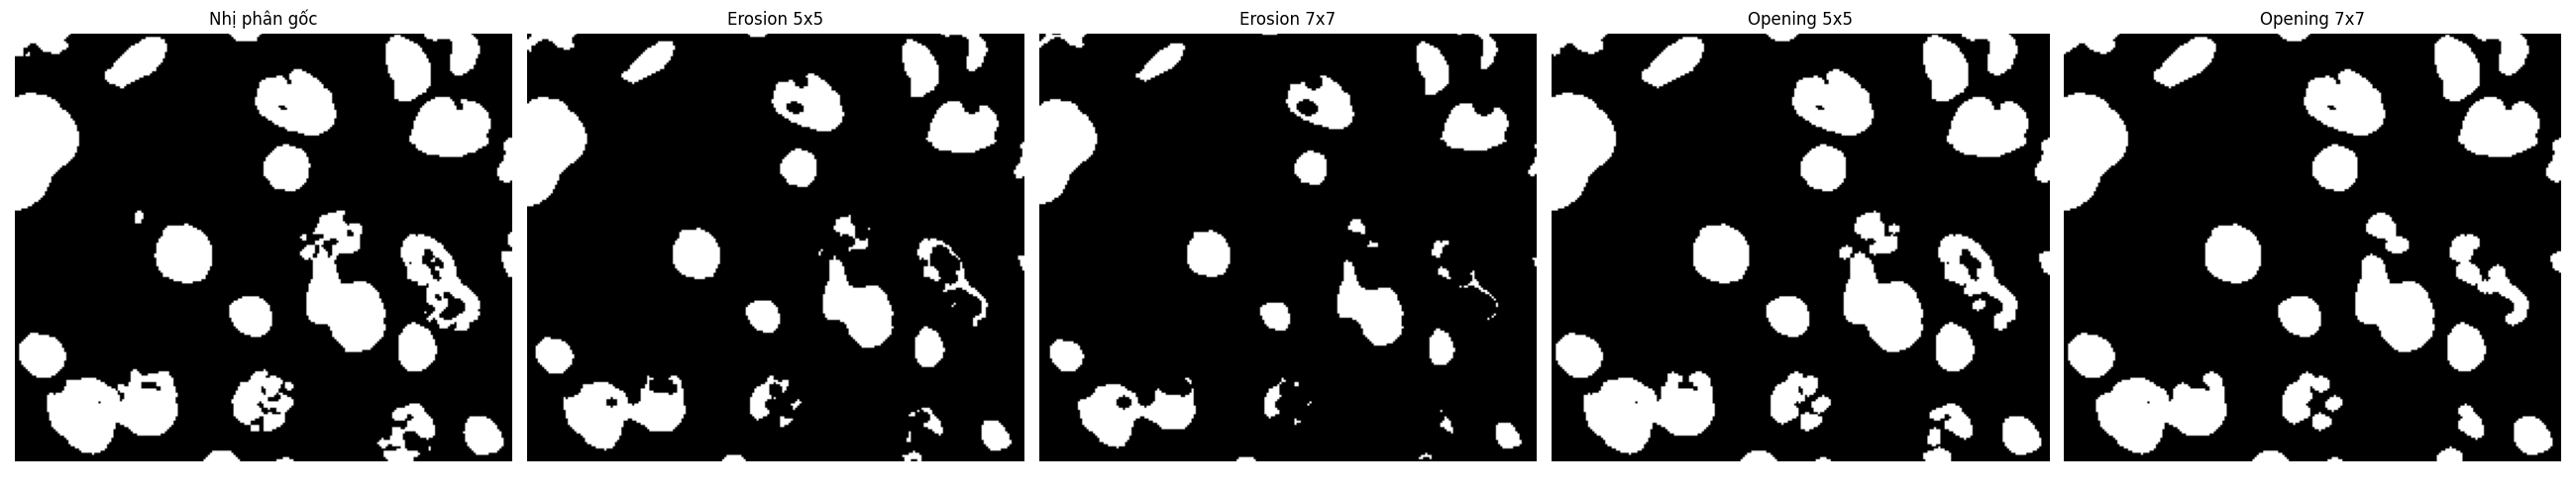

In [ ]:
# Phóng to một vùng có các cặp nhân dính nhau để nhìn rõ chỗ tách (đổi y1, y2, x1, x2 để chọn vùng khác)
y1, y2, x1, x2 = 280, 480, 380, 612

vung = [anh[y1:y2, x1:x2] for anh in [binary, co[1], co[2], mo_opencv[1], mo_opencv[2]]]
show_images(vung, ["Nhị phân gốc", "Erosion 5x5", "Erosion 7x7", "Opening 5x5", "Opening 7x7"], figsize=(26, 5))

Nhận xét và giải thích: tách các nhân dính nhau (ảnh cell1, kernel ellipse)

**1. Bảng kết quả** (chỉ tính đối tượng từ 100 điểm ảnh trở lên là một nhân, ảnh gốc có 127 nhân và diện tích 74554)

| Phép | Diện tích | Thay đổi | Số nhân |
|---|---|---|---|
| Erosion 3x3 | 61351 | -17.7% | 124 |
| Erosion 5x5 | 46305 | -37.9% | 116 |
| Erosion 7x7 | 36312 | -51.3% | 103 |
| Erosion 9x9 | 26243 | -64.8% | 82 |
| Erosion -> Dilation 3x3 (= Opening) | 73997 | -0.7% | 127 |
| Erosion -> Dilation 5x5 (= Opening) | 71864 | -3.6% | 130 |
| Erosion -> Dilation 7x7 (= Opening) | 68981 | -7.5% | 130 |
| Erosion -> Dilation 9x9 (= Opening) | 64932 | -12.9% | 126 |
| Co 7x7, giãn 5x5 | 58110 | -22.1% | 128 |
| Co 7x7, giãn 3x3 | 45444 | -39.0% | 116 |
| Co 3x3 x2 lần, giãn 3x3 x1 lần | 60510 | -18.8% | 127 |
| Opening 3x3, iterations=2 | 72210 | -3.1% | 128 |

**2. So sánh**
- **Erosion:** kernel càng lớn thì diện tích càng giảm mạnh (từ -17.7% đến -64.8%) và số nhân đếm được giảm (từ 127 xuống 82) vì các nhân nhỏ bị co biến mất. Erosion một mình tách được cầu hẹp nhưng làm sai kích thước.
- **Erosion rồi Dilation cùng kernel:** diện tích được phục hồi về gần gốc (-0.7% đến -12.9%) và số nhân tăng nhẹ lên 130 ở kernel 5x5 và 7x7. Ảnh phóng to cho thấy các cặp dính bằng cổ dày vẫn còn dính sau 7x7; số nhân tăng một phần là do nhân có nhiều chấm sáng bị vỡ thành các mảnh, chưa chắc toàn bộ là tách đúng từng cặp.
- **So với Opening:** kiểm chứng bằng code, erode rồi dilate cùng kernel và cùng iterations cho kết quả giống hệt `cv2.morphologyEx(MORPH_OPEN)` ở cả bốn kernel (np.array_equal là True, cv2.absdiff bằng 0 điểm ảnh). Kết quả chỉ khác khi co và giãn dùng kernel hoặc iterations khác nhau: co 7x7 giãn 5x5 mất 22.1% diện tích, giãn 3x3 mất 39.0%, co 3x3 hai lần rồi giãn một lần mất 18.8%, trong khi co và giãn đều 2 lần (giống Opening iterations=2) chỉ mất 3.1%.

**3. Giải thích**
Opening được định nghĩa đúng là erosion rồi dilation với cùng kernel, nên khi cùng tham số hai kết quả giống hệt nhau, và tự viết hai bước cũng không có lợi thế gì thêm. Opening hiệu quả hơn chuỗi tự thiết kế khi chuỗi đó dùng tham số lệch (kernel hoặc iterations khác nhau), vì phép giãn không trả lại đúng phần đã co, làm vật thể nhỏ đi và có thể sai hình dạng; dùng Opening thì sự đối xứng này được đảm bảo, phần mất đi chỉ là những chi tiết nhỏ hơn kernel. Chuỗi tự thiết kế chỉ có ý nghĩa khi cố ý muốn khác Opening, ví dụ giữ ảnh sau co để làm điểm đánh dấu từng nhân cho bước xử lý khác.

**Kết luận:** muốn tách các nhân dính nhẹ mà vẫn giữ kích thước thì dùng Opening, kernel 5x5 hoặc 7x7 là hợp lý trên ảnh này (số nhân 130, diện tích -3.6% đến -7.5%). Các cặp dính bằng cổ rộng cần kernel lớn hơn, nhưng kernel 9x9 đã làm mất 12.9% diện tích và giảm số nhân.

##16.5 Bài tập 5. Phân tích ảnh hưởng của hình dạng kernel

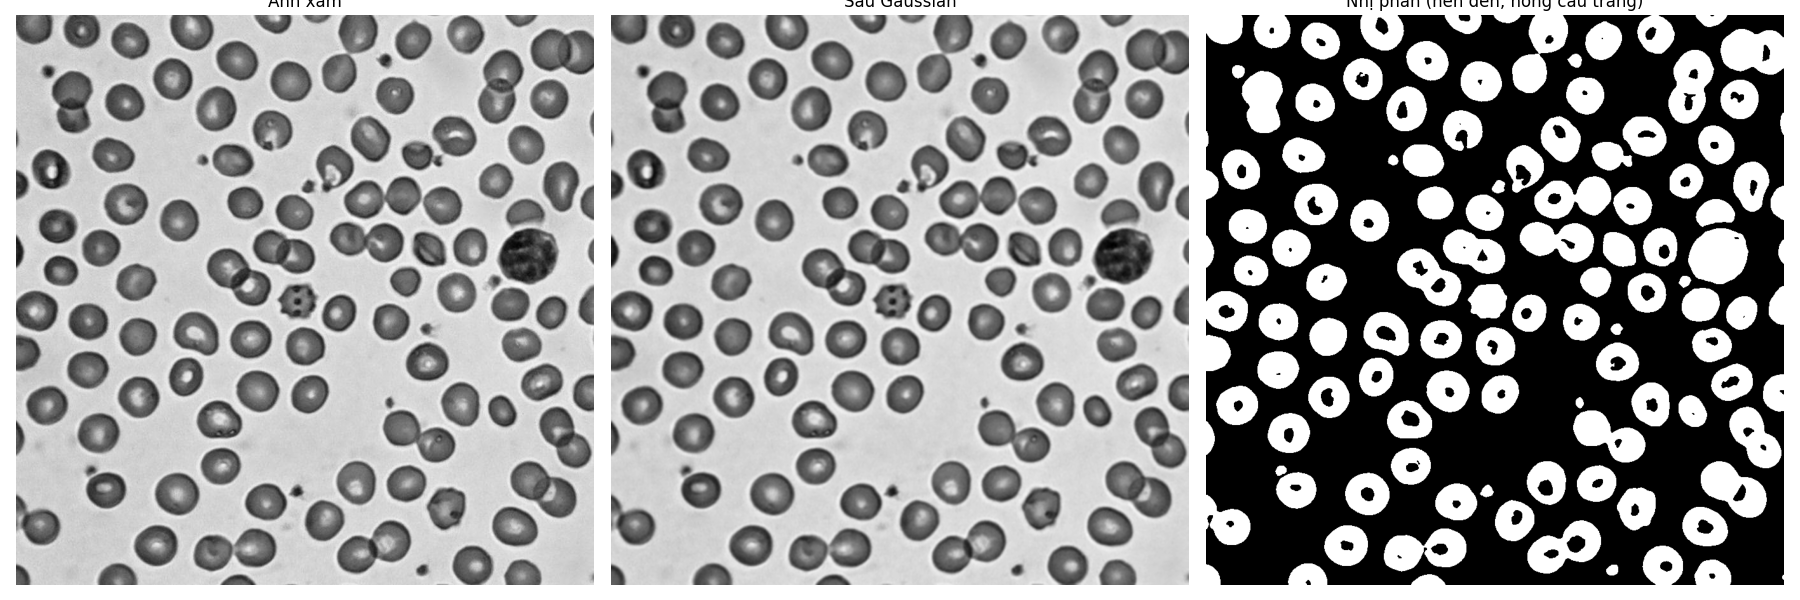

In [ ]:
# Đọc ảnh hồng cầu, làm mờ Gaussian và ngưỡng hóa Otsu (nền đen, hồng cầu trắng)
img = cv2.imread("/content/RBC2.jpg", cv2.IMREAD_GRAYSCALE)
blur = cv2.GaussianBlur(img, (5, 5), 0)
_, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

show_images([img, blur, binary], ["Ảnh xám", "Sau Gaussian", "Nhị phân (nền đen, hồng cầu trắng)"], figsize=(18, 6))

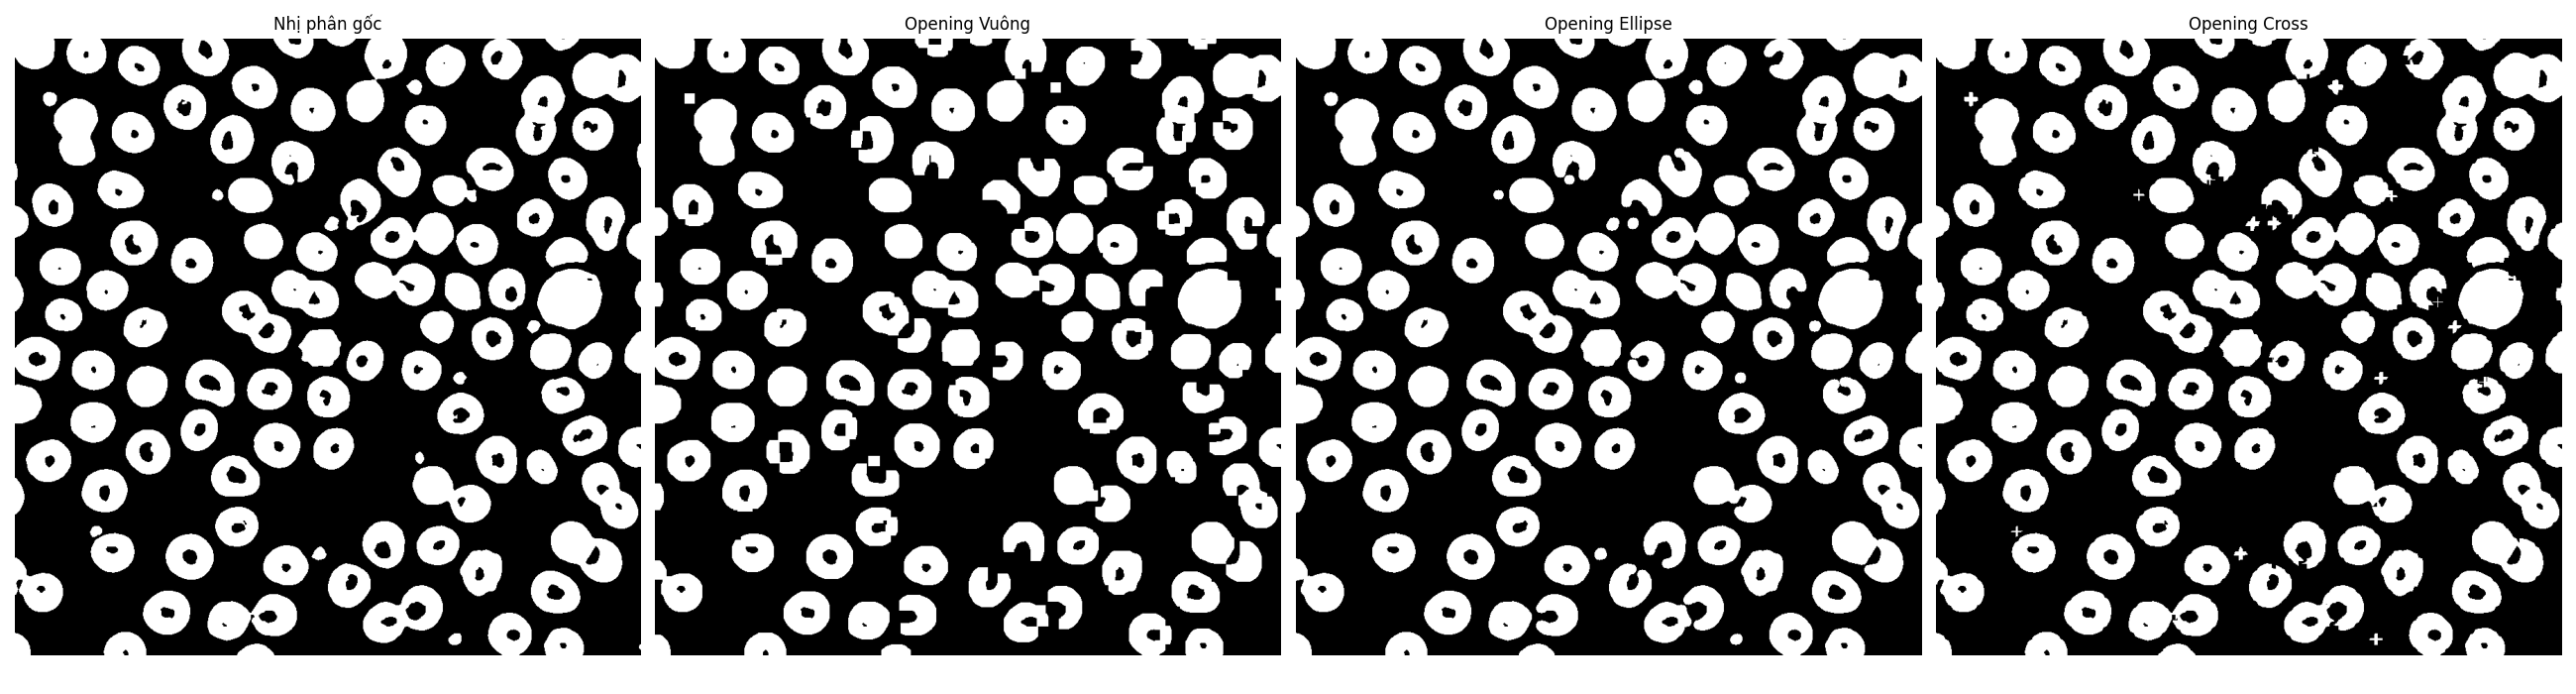

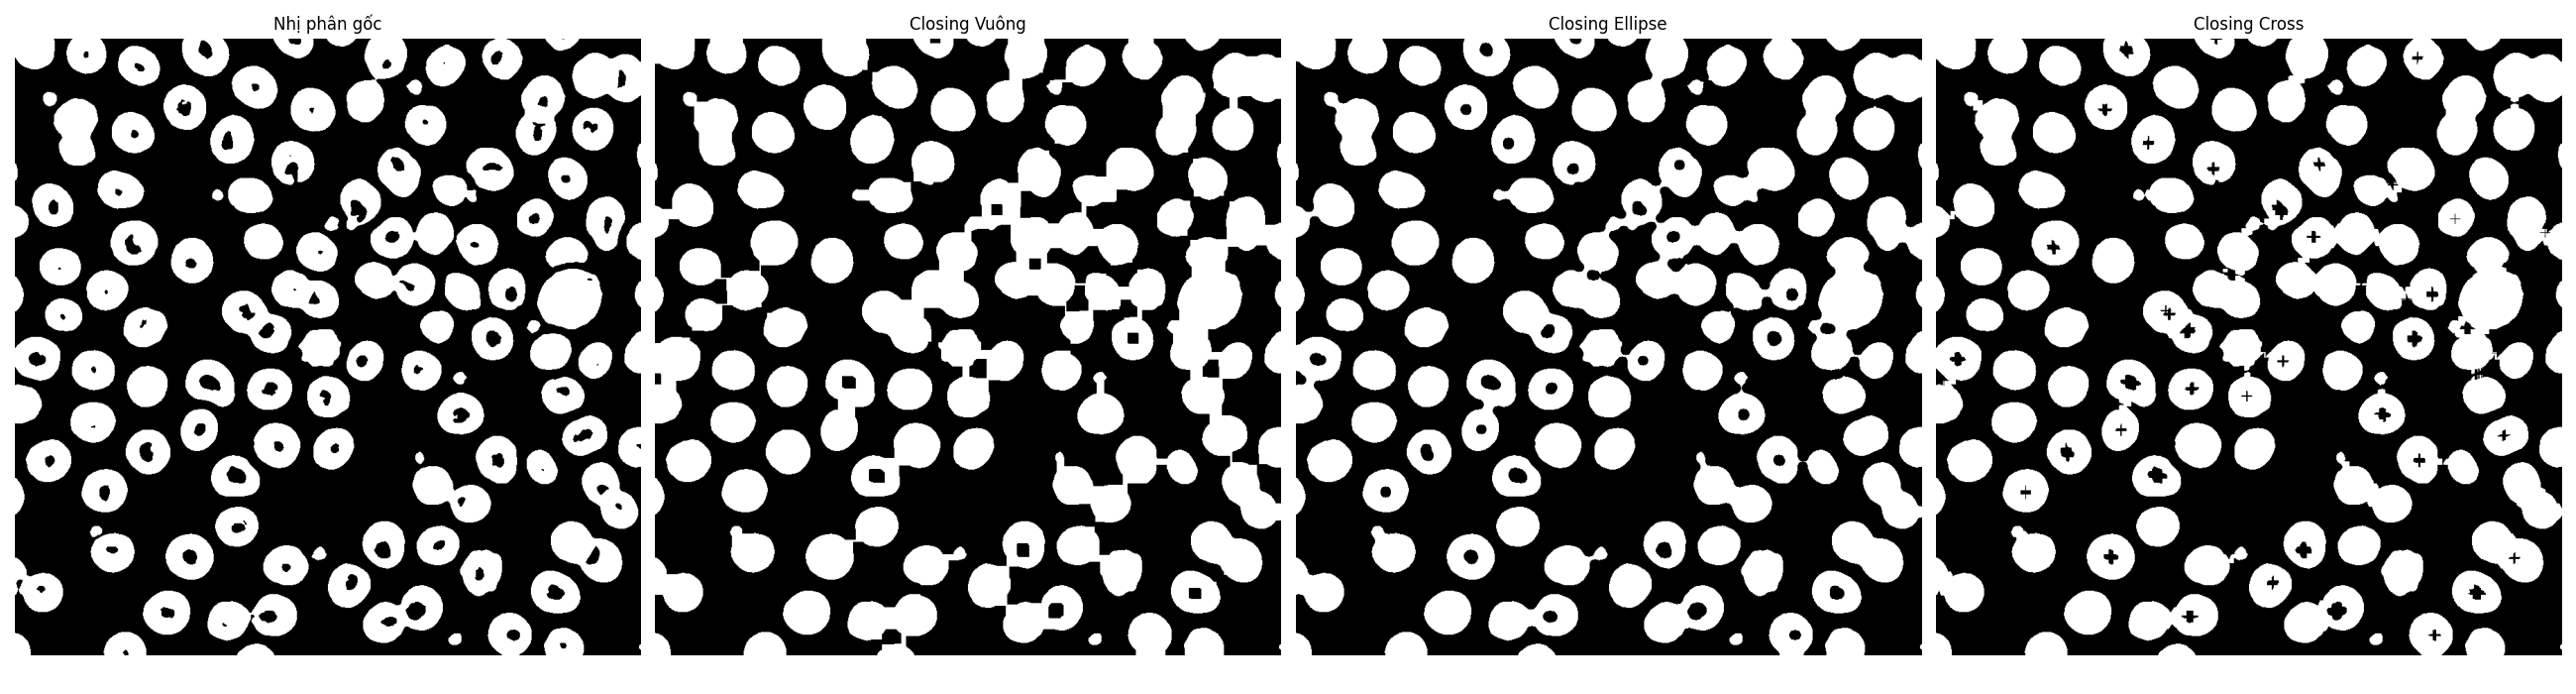

In [ ]:
# Opening và closing với kernel vuông, ellipse, cross cùng kích thước 15x15
kich_thuoc = (15, 15)
kernels = [
    ("Vuông", cv2.getStructuringElement(cv2.MORPH_RECT, kich_thuoc)),
    ("Ellipse", cv2.getStructuringElement(cv2.MORPH_ELLIPSE, kich_thuoc)),
    ("Cross", cv2.getStructuringElement(cv2.MORPH_CROSS, kich_thuoc)),
]

opening = [cv2.morphologyEx(binary, cv2.MORPH_OPEN, k) for ten, k in kernels]
closing = [cv2.morphologyEx(binary, cv2.MORPH_CLOSE, k) for ten, k in kernels]

show_images([binary] + opening, ["Nhị phân gốc"] + [f"Opening {ten}" for ten, k in kernels], figsize=(26, 7))
show_images([binary] + closing, ["Nhị phân gốc"] + [f"Closing {ten}" for ten, k in kernels], figsize=(26, 7))

In [ ]:
# Đo độ tròn 4*pi*diện tích/chu vi^2, số lỗ nhỏ, số chấm nhiễu và diện tích của từng kết quả
dt_nho = 100
dt_lo = 500

def do_dac_trung(anh):
    contours, hierarchy = cv2.findContours(anh, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
    h_img, w_img = anh.shape
    do_tron = []
    so_nhieu = so_lo_nho = 0
    for c, h in zip(contours, hierarchy[0]):
        dt = cv2.contourArea(c)
        if h[3] != -1:
            so_lo_nho += dt < dt_lo
            continue
        if dt < dt_nho:
            so_nhieu += 1
            continue
        x, y, w, h_ = cv2.boundingRect(c)
        if x > 0 and y > 0 and x + w < w_img and y + h_ < h_img:
            do_tron.append(4 * np.pi * dt / cv2.arcLength(c, True) ** 2)
    return cv2.countNonZero(anh), so_nhieu, so_lo_nho, len(do_tron), np.mean(do_tron), np.median(do_tron)

area_goc = cv2.countNonZero(binary)
danh_sach = [("Nhị phân gốc", binary)]
danh_sach += [(f"Opening {ten}", anh) for (ten, k), anh in zip(kernels, opening)]
danh_sach += [(f"Closing {ten}", anh) for (ten, k), anh in zip(kernels, closing)]

print(f"{'Ảnh':<20}{'Diện tích':>11}{'Thay đổi':>10}{'Chấm nhiễu':>12}{'Lỗ nhỏ':>8}{'Số tế bào':>11}{'Độ tròn TB':>12}{'Trung vị':>10}")
for ten, anh in danh_sach:
    dt, n_nhieu, n_lo, n_tb, tron, tron_tv = do_dac_trung(anh)
    print(f"{ten:<20}{dt:>11}{(dt - area_goc) / area_goc * 100:>9.1f}%{n_nhieu:>12}{n_lo:>8}{n_tb:>11}{tron:>12.3f}{tron_tv:>10.3f}")
print(f"(Chấm nhiễu: đối tượng nhỏ hơn {dt_nho} điểm ảnh; lỗ nhỏ: nhỏ hơn {dt_lo} điểm ảnh; độ tròn chỉ tính cho tế bào không chạm mép ảnh)")

Ảnh                   Diện tích  Thay đổi  Chấm nhiễu  Lỗ nhỏ  Số tế bào  Độ tròn TB  Trung vị
Nhị phân gốc             290767      0.0%           2      81         89       0.833     0.879
Opening Vuông            272706     -6.2%           0      57         90       0.773     0.847
Opening Ellipse          286312     -1.5%           0      69         92       0.809     0.878
Opening Cross            283688     -2.4%           4      79         87       0.745     0.846
Closing Vuông            320248     10.1%           2       8         43       0.717     0.849
Closing Ellipse          305505      5.1%           2      24         65       0.785     0.880
Closing Cross            306304      5.3%           5      34         68       0.771     0.878
(Chấm nhiễu: đối tượng nhỏ hơn 100 điểm ảnh; lỗ nhỏ: nhỏ hơn 500 điểm ảnh; độ tròn chỉ tính cho tế bào không chạm mép ảnh)


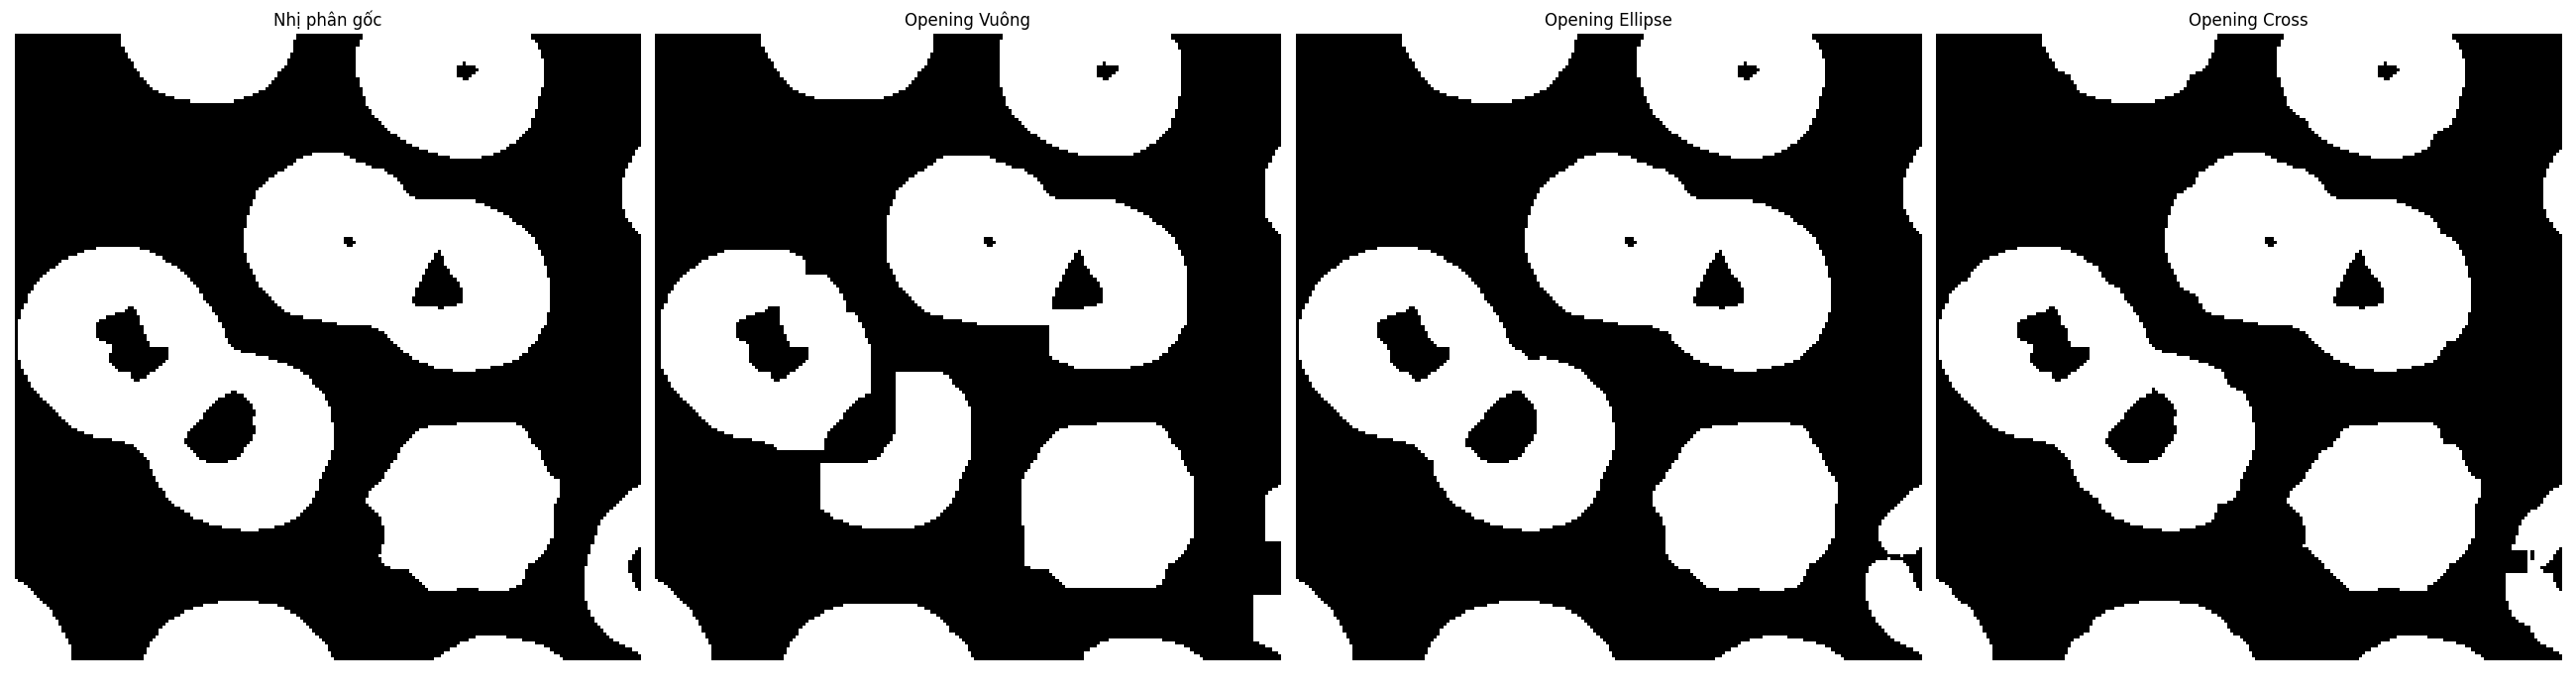

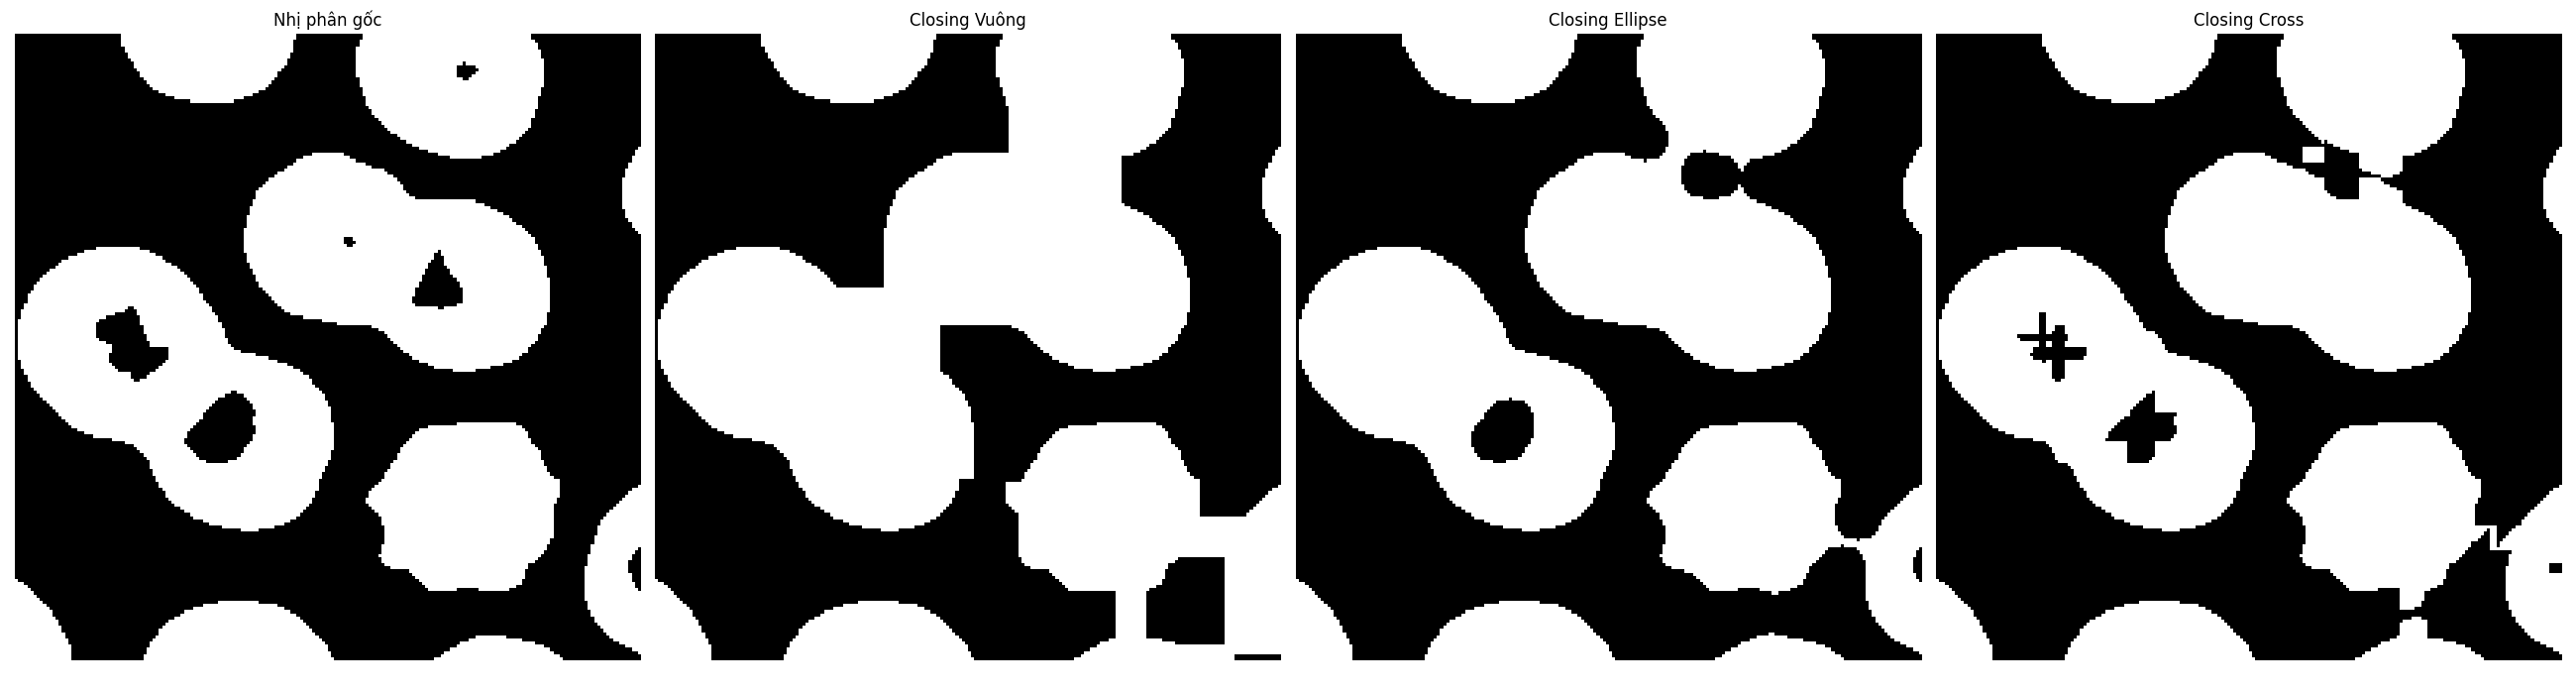

In [ ]:
# Phóng to một vùng để so sánh biên của opening và closing với ba loại kernel (đổi y1, y2, x1, x2 để chọn vùng khác)
y1, y2, x1, x2 = 300, 500, 300, 500

show_images([binary[y1:y2, x1:x2]] + [anh[y1:y2, x1:x2] for anh in opening], ["Nhị phân gốc"] + [f"Opening {ten}" for ten, k in kernels], figsize=(26, 7))
show_images([binary[y1:y2, x1:x2]] + [anh[y1:y2, x1:x2] for anh in closing], ["Nhị phân gốc"] + [f"Closing {ten}" for ten, k in kernels], figsize=(26, 7))

Nhận xét và giải thích: ảnh hưởng của hình dạng kernel (ảnh RBC2, kernel 15x15)

**1. Bảng kết quả** (độ tròn = 4*pi*diện tích/chu vi^2, chỉ tính tế bào không chạm mép ảnh; lỗ nhỏ là lỗ dưới 500 điểm ảnh)

| Ảnh | Diện tích | Thay đổi | Lỗ nhỏ | Số tế bào | Độ tròn TB | Độ tròn trung vị |
|---|---|---|---|---|---|---|
| Nhị phân gốc | 290767 | 0.0% | 81 | 89 | 0.833 | 0.879 |
| Opening vuông | 272706 | -6.2% | 57 | 90 | 0.773 | 0.847 |
| Opening ellipse | 286312 | -1.5% | 69 | 92 | 0.809 | 0.878 |
| Opening cross | 283688 | -2.4% | 79 | 87 | 0.745 | 0.846 |
| Closing vuông | 320248 | +10.1% | 8 | 43 | 0.717 | 0.849 |
| Closing ellipse | 305505 | +5.1% | 24 | 65 | 0.785 | 0.880 |
| Closing cross | 306304 | +5.3% | 34 | 68 | 0.771 | 0.878 |

**2. So sánh**
- **Độ tự nhiên của biên:** ở ảnh phóng to, Closing vuông tạo biên có góc vuông và nối các tế bào thành khối vuông vức; Closing cross để lại các lỗ hình chữ thập và vài mảnh vụn nhỏ; Closing ellipse cho biên cong tự nhiên nhất.
- **Khả năng giữ hình dạng gần tròn:** độ tròn trung vị của ellipse gần như không đổi (0.878 và 0.880 so với 0.879 ban đầu), còn kernel vuông thấp hơn (0.847 và 0.849). Cross có độ tròn trung vị 0.846 sau Opening nhưng 0.878 sau Closing. Độ tròn trung bình còn bị ảnh hưởng bởi việc số tế bào thay đổi (Closing nối tế bào), nên trung vị đáng tin hơn.
- **Mức xóa nhiễu và lấp lỗ:** Opening vuông làm mòn nhiều nhất (-6.2% diện tích), ellipse chỉ -1.5%. Về lấp lỗ, Closing vuông lấp nhiều nhất (còn 8 lỗ) nhưng nối tế bào mạnh nhất (số tế bào giảm từ 89 xuống 43); ellipse còn 24 lỗ và 65 tế bào; cross còn 34 lỗ và 68 tế bào. Kernel vuông lấp lỗ tốt nhưng đánh đổi bằng việc dính tế bào và méo hình.
- Nhận xét dựa trên một ảnh và một kích thước kernel (15x15).

**3. Giải thích**
Kernel ellipse có dạng gần tròn và đối xứng theo mọi hướng, nên khi tác động lên vật thể tròn như hồng cầu, bạch cầu hay nhân tế bào thì biên bị co hoặc giãn đều theo mọi hướng, ít tạo góc và không ưu tiên hướng ngang dọc. Kernel vuông có góc nên tác động mạnh hơn theo hướng chéo, tạo góc cạnh trên biên và nối các tế bào ở khoảng cách chéo; kernel cross chỉ có hai nhánh mảnh nên tác động yếu ở góc chéo, lấp lỗ hay khử nhiễu không đều và để lại hình chữ thập. Vì vậy với bài toán đo diện tích, hình dạng hay đếm tế bào, kernel ellipse thường hợp lý hơn vì sai lệch hình học nhỏ nhất.

**Kết luận:** kernel ellipse giữ hình tròn và diện tích tốt nhất trong ba loại ở ảnh này.